<a href="https://colab.research.google.com/github/rabnawaz172/MNER_2/blob/main/Effi_resnet34_augumentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
mport kagglehub

# Download the latest version of the competition files
path = kagglehub.competition_download('recodai-luc-scientific-image-forgery-detection')

print("Path to competition files:", path)

In [ ]:
# ==============================================================
# CELL 1: DATASET LOADING & EXACT SEQUENTIAL SPLIT
# ==============================================================

import os
import cv2
import numpy as np
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset

# -----------------------------
# Configuration & Paths
# -----------------------------
BASE_DIR_TRAIN = Path("/home/rab/Downloads/forgery_data2_")  # Train & Val source

IMG_SIZE = (256, 256)
RANDOM_STATE = 42

# -----------------------------
# Dataset & Mask Utilities
# -----------------------------
def find_mask_file(mask_dir, img_name):
    stem = Path(img_name).stem
    for p in [f"{stem}.npy", f"{stem}_mask.npy"]:
        path = os.path.join(mask_dir, p)
        if os.path.exists(path):
            return path
    for root, _, files in os.walk(mask_dir):
        for f in files:
            if Path(f).stem == stem:
                return os.path.join(root, f)
    return None

def load_mask_safe(mask_path, target_shape):
    if mask_path is None or not os.path.exists(mask_path):
        return np.zeros(target_shape, dtype=np.uint8)
    mask = np.squeeze(np.load(mask_path, allow_pickle=True))
    if mask.ndim > 2:
        mask = mask[..., 0]
    mask = (mask > 0.5).astype(np.uint8)
    if mask.shape != target_shape:
        mask = cv2.resize((mask * 255).astype(np.uint8), (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)
    return mask

class ForgerySegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, img_size=IMG_SIZE):
        self.img_size = img_size
        self.image_paths = []
        for folder in ["authentic", "forged"]:
            folder_path = Path(image_dir) / folder
            if folder_path.is_dir():
                for file in sorted(os.listdir(folder_path)):
                    if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                        self.image_paths.append(str(folder_path / file))
        self.mask_paths = [find_mask_file(mask_dir, Path(x).name) for x in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = cv2.imread(self.image_paths[index])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.img_size[1], self.img_size[0]))
        mask = load_mask_safe(self.mask_paths[index], (self.img_size[0], self.img_size[1]))
        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        mask = torch.from_numpy(mask).unsqueeze(0).float()
        return image, mask

def get_image_class_from_path(img_path):
    return 1 if "forged" in Path(img_path).parts else 0

# -----------------------------
# Execute Split
# -----------------------------
dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
targets = [get_image_class_from_path(p) for p in dataset.image_paths]

# Step 1: 20% validation pool, 80% training pool
train_pool_idx, val_idx = train_test_split(
    list(range(len(dataset))),
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=targets
)

# Step 2: 25% test set from the training pool
train_pool_targets = [targets[i] for i in train_pool_idx]
train_idx, test_idx = train_test_split(
    train_pool_idx,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=train_pool_targets
)

# Statistics display
train_labels = [targets[i] for i in train_idx]
test_labels = [targets[i] for i in test_idx]
val_labels = [targets[i] for i in val_idx]

print("=" * 70)
print("📊 DATASET SPLIT STATISTICS (20% Val, then 25% Test from Train)")
print("=" * 70)
print(f"Total Dataset Images          : {len(dataset)}")
print("-" * 70)
print(f"1. Final Training Set (75% of Train Pool) : {len(train_idx)} images")
print(f"   - Authentic                : {Counter(train_labels)[0]}")
print(f"   - Forged                   : {Counter(train_labels)[1]}")
print("-" * 70)
print(f"2. Test Set (25% of Train Pool)           : {len(test_idx)} images")
print(f"   - Authentic                : {Counter(test_labels)[0]}")
print(f"   - Forged                   : {Counter(test_labels)[1]}")
print("-" * 70)
print(f"3. Validation Set (Direct 20%)            : {len(val_idx)} images")
print(f"   - Authentic                : {Counter(val_labels)[0]}")
print(f"   - Forged                   : {Counter(val_labels)[1]}")
print("=" * 70)
print(f"Sum Check: Train ({len(train_idx)}) + Test ({len(test_idx)}) + Val ({len(val_idx)}) = {len(train_idx) + len(test_idx) + len(val_idx)} (Matches Total)")
print("=" * 70)


📊 DATASET SPLIT STATISTICS (20% Val, then 25% Test from Train)
Total Dataset Images          : 5128
----------------------------------------------------------------------
1. Final Training Set (75% of Train Pool) : 3076 images
   - Authentic                : 1426
   - Forged                   : 1650
----------------------------------------------------------------------
2. Test Set (25% of Train Pool)           : 1026 images
   - Authentic                : 475
   - Forged                   : 551
----------------------------------------------------------------------
3. Validation Set (Direct 20%)            : 1026 images
   - Authentic                : 476
   - Forged                   : 550
Sum Check: Train (3076) + Test (1026) + Val (1026) = 5128 (Matches Total)


In [ ]:
import os
import cv2
import numpy as np
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, Subset
import torch

# -----------------------------
# Configuration & Paths
# -----------------------------
BASE_DIR_TRAIN = Path("/home/rab/Downloads/forgery_data2_")
TRAIN_IMAGE_DIR = BASE_DIR_TRAIN / "train_images"
TRAIN_MASK_DIR  = BASE_DIR_TRAIN / "train_masks"

IMG_SIZE = (256, 256)
RANDOM_STATE = 42
VAL_SPLIT = 0.20
TEST_FRACTION = 0.25

# -----------------------------
# Dataset & Mask Utilities
# -----------------------------
def find_mask_file(mask_dir, img_name):
    stem = Path(img_name).stem
    for p in [f"{stem}.npy", f"{stem}_mask.npy"]:
        path = os.path.join(mask_dir, p)
        if os.path.exists(path):
            return path
    for root, _, files in os.walk(mask_dir):
        for f in files:
            if Path(f).stem == stem:
                return os.path.join(root, f)
    return None

def load_mask_safe(mask_path, target_shape):
    if mask_path is None or not os.path.exists(mask_path):
        return np.zeros(target_shape, dtype=np.uint8)
    mask = np.squeeze(np.load(mask_path, allow_pickle=True))
    if mask.ndim > 2:
        mask = mask[..., 0]
    mask = (mask > 0.5).astype(np.uint8)
    if mask.shape != target_shape:
        mask = cv2.resize((mask * 255).astype(np.uint8), (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)
    return mask

class ForgerySegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, img_size=IMG_SIZE):
        self.img_size = img_size
        self.image_paths = []
        for folder in ["authentic", "forged"]:
            folder_path = Path(image_dir) / folder
            if folder_path.is_dir():
                for file in sorted(os.listdir(folder_path)):
                    if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                        self.image_paths.append(str(folder_path / file))
        self.mask_paths = [find_mask_file(mask_dir, Path(x).name) for x in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = cv2.imread(self.image_paths[index])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.img_size[1], self.img_size[0]))
        mask = load_mask_safe(self.mask_paths[index], (self.img_size[0], self.img_size[1]))
        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        mask = torch.from_numpy(mask).unsqueeze(0).float()
        return image, mask

def get_image_class_from_path(img_path):
    return 1 if "forged" in Path(img_path).parts else 0

# -----------------------------
# Execute Split & Statistics
# -----------------------------
dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
targets = [get_image_class_from_path(p) for p in dataset.image_paths]

# Step 1: 20% validation set, 80% training pool
train_pool_idx, val_idx = train_test_split(
    list(range(len(dataset))),
    test_size=VAL_SPLIT,
    random_state=RANDOM_STATE,
    stratify=targets
)

# Step 2: 25% test set from the training pool
train_pool_targets = [targets[i] for i in train_pool_idx]
train_idx, test_idx = train_test_split(
    train_pool_idx,
    test_size=TEST_FRACTION,
    random_state=RANDOM_STATE,
    stratify=train_pool_targets
)

# Subsets
train_subset = Subset(dataset, train_idx)
val_subset = Subset(dataset, val_idx)
test_subset = Subset(dataset, test_idx)

# Statistics display
train_labels = [targets[i] for i in train_idx]
test_labels = [targets[i] for i in test_idx]
val_labels = [targets[i] for i in val_idx]

print("=" * 70)
print("📊 DATASET SPLIT STATISTICS (20% Val, then 25% Test from Train)")
print("=" * 70)
print(f"Total Dataset Images                  : {len(dataset)}")
print("-" * 70)
print(f"1. Final Training Set (75% of Train Pool) : {len(train_idx)} images")
print(f"   - Authentic                        : {Counter(train_labels)[0]}")
print(f"   - Forged                           : {Counter(train_labels)[1]}")
print("-" * 70)
print(f"2. Test Set (25% of Train Pool)           : {len(test_idx)} images")
print(f"   - Authentic                        : {Counter(test_labels)[0]}")
print(f"   - Forged                           : {Counter(test_labels)[1]}")
print("-" * 70)
print(f"3. Validation Set (Direct 20%)            : {len(val_idx)} images")
print(f"   - Authentic                        : {Counter(val_labels)[0]}")
print(f"   - Forged                           : {Counter(val_labels)[1]}")
print("=" * 70)
print(f"Sum Check: Train ({len(train_idx)}) + Test ({len(test_idx)}) + Val ({len(val_idx)}) = {len(train_idx) + len(test_idx) + len(val_idx)} (Matches Total)")
print("=" * 70)

📊 DATASET SPLIT STATISTICS (20% Val, then 25% Test from Train)
Total Dataset Images                  : 5128
----------------------------------------------------------------------
1. Final Training Set (75% of Train Pool) : 3076 images
   - Authentic                        : 1426
   - Forged                           : 1650
----------------------------------------------------------------------
2. Test Set (25% of Train Pool)           : 1026 images
   - Authentic                        : 475
   - Forged                           : 551
----------------------------------------------------------------------
3. Validation Set (Direct 20%)            : 1026 images
   - Authentic                        : 476
   - Forged                           : 550
Sum Check: Train (3076) + Test (1026) + Val (1026) = 5128 (Matches Total)


Using Device: cuda


/home/rab/gpu_env/lib/python3.10/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)



Starting Training with EfficientNet-B0 + Augmentation & Early Stopping...


Epoch 1: Train Loss 1.3911 | Val Loss 1.1675
✅ Saved best model (Val Loss: 1.1675)


Epoch 2: Train Loss 1.1216 | Val Loss 1.0604
✅ Saved best model (Val Loss: 1.0604)


...

Epoch 40: Train Loss 0.8505 | Val Loss 0.8899
⚠️ Validation loss did not improve. Patience: 4/8


Epoch 41: Train Loss 0.8493 | Val Loss 0.8923
⚠️ Validation loss did not improve. Patience: 5/8


Epoch 42: Train Loss 0.8472 | Val Loss 0.8875
⚠️ Validation loss did not improve. Patience: 6/8


Epoch 43: Train Loss 0.8506 | Val Loss 0.8898
⚠️ Validation loss did not improve. Patience: 7/8


Epoch 44: Train Loss 0.8517 | Val Loss 0.8882
⚠️ Validation loss did not improve. Patience: 8/8

🛑 Early stopping triggered at epoch 44 to prevent overfitting!


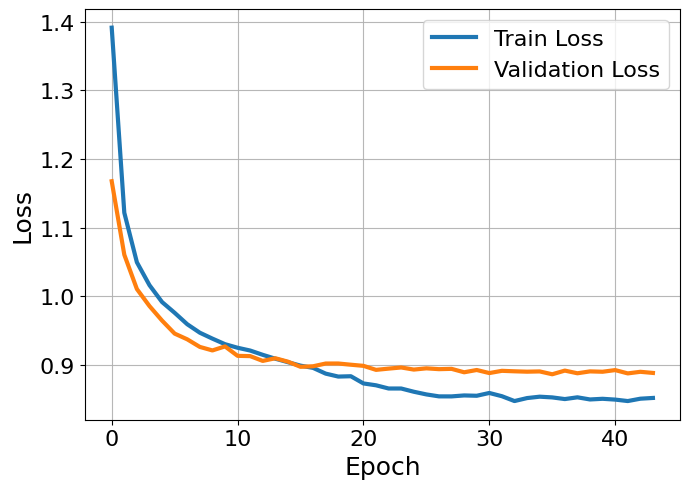


✅ Loss plot saved to: /home/rab/Downloads/forgery_10_octiber_effi/augumentation/loss_.png


In [ ]:
# ==============================================================
# IMAGE FORGERY DETECTION TRAINING (EFFICIENTNET + AUGMENTATION & EARLY STOPPING)
# ==============================================================

import sys
import os
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import torch.optim as optim
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import albumentations as A

# -----------------------------
# Paths Configuration & User Config
# -----------------------------
BASE_DIR_TRAIN = Path("/home/rab/Downloads/forgery_data2_")  # Train & Val source
BASE_DIR_TEST  = Path("/home/rab/Downloads/forgery_data")    # Original Test source

TRAIN_IMAGE_DIR = BASE_DIR_TRAIN / "train_images"
TRAIN_MASK_DIR  = BASE_DIR_TRAIN / "train_masks"

TEST_IMAGE_DIR  = BASE_DIR_TEST / "test_images"
TEST_MASK_DIR   = BASE_DIR_TEST / "test_masks"

OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi/augumentation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE = (256, 256)
BATCH_SIZE = 8
NUM_EPOCHS = 50
RANDOM_STATE = 42
NUM_WORKERS = 0  # Set to 0 to avoid multiprocessing pickling issues
VAL_SPLIT = 0.20  # 20% validation split
LR = 5e-5
EARLY_STOPPING_PATIENCE = 8  # Stop if validation loss doesn't improve for 8 epochs

MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, "effinet_model.pth")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print(f"Using Device: {DEVICE}")


# -----------------------------
# Dataset & Augmentation Utilities
# -----------------------------
def find_mask_file(mask_dir, img_name):
    stem = Path(img_name).stem
    for p in [f"{stem}.npy", f"{stem}_mask.npy"]:
        path = os.path.join(mask_dir, p)
        if os.path.exists(path):
            return path
    for root, _, files in os.walk(mask_dir):
        for f in files:
            if Path(f).stem == stem:
                return os.path.join(root, f)
    return None

def load_mask_safe(mask_path, target_shape):
    if mask_path is None or not os.path.exists(mask_path):
        return np.zeros(target_shape, dtype=np.uint8)
    mask = np.squeeze(np.load(mask_path, allow_pickle=True))
    if mask.ndim > 2:
        mask = mask[..., 0]
    mask = (mask > 0.5).astype(np.uint8)
    if mask.shape != target_shape:
        mask = cv2.resize((mask * 255).astype(np.uint8), (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)
    return mask

# Define augmentation pipelines using Albumentations
train_transform = A.Compose([
    A.Resize(IMG_SIZE[0], IMG_SIZE[1]),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=0.5, border_mode=cv2.BORDER_REFLECT_101),
    A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, p=0.3),
], is_check_shapes=False)

val_transform = A.Compose([
    A.Resize(IMG_SIZE[0], IMG_SIZE[1]),
], is_check_shapes=False)

class ForgerySegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.transform = transform
        self.image_paths = []

        for folder in ["authentic", "forged"]:
            folder_path = Path(image_dir) / folder
            if folder_path.is_dir():
                for file in sorted(os.listdir(folder_path)):
                    if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                        self.image_paths.append(str(folder_path / file))

        self.mask_paths = [find_mask_file(mask_dir, Path(x).name) for x in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = cv2.imread(self.image_paths[index])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = load_mask_safe(self.mask_paths[index], IMG_SIZE)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        mask = torch.from_numpy(mask).unsqueeze(0).float()

        return image, mask

def get_image_class_from_path(img_path):
    return 1 if "forged" in Path(img_path).parts else 0

# Load dataset and create 80/20 train/val split with separate transforms
full_train_dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, transform=train_transform)
full_val_dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, transform=val_transform)
test_dataset = ForgerySegmentationDataset(TEST_IMAGE_DIR, TEST_MASK_DIR, transform=val_transform)

targets = [get_image_class_from_path(p) for p in full_train_dataset.image_paths]

train_idx, val_idx = train_test_split(
    list(range(len(full_train_dataset))),
    test_size=VAL_SPLIT,
    random_state=RANDOM_STATE,
    stratify=targets
)

train_subset = Subset(full_train_dataset, train_idx)
val_subset = Subset(full_val_dataset, val_idx)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=False)
val_loader   = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=False)


# -----------------------------
# Loss Function & Model Architecture
# -----------------------------
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-7):
        super().__init__()
        self.eps = eps
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)
        intersection = (probs * targets).sum(dim=1)
        union = probs.sum(dim=1) + targets.sum(dim=1)
        loss = 1 - ((2 * intersection + self.eps) / (union + self.eps))
        return loss.mean()

model = smp.Unet(
    encoder_name="efficientnet-b0",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

bce = nn.BCEWithLogitsLoss()
dice = DiceLoss()

def combined_loss(logits, targets):
    return bce(logits, targets) + dice(logits, targets)

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.3, patience=3, min_lr=1e-6)
scaler = torch.amp.GradScaler('cuda' if DEVICE.type=='cuda' else None)


# -----------------------------
# Training Loop with Early Stopping
# -----------------------------
best_val = 1e9
patience_counter = 0
train_losses_all, val_losses_all = [], []

print("\nStarting Training with EfficientNet-B0 + Augmentation & Early Stopping...")
for epoch in range(1, NUM_EPOCHS+1):
    # TRAIN
    model.train()
    train_losses = []
    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch} TRAIN", leave=False):
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()

        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type=='cuda'):
            logits = model(images)
            if logits.shape[2:] != masks.shape[2:]:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')
            loss = combined_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_losses.append(loss.item())

    # VALIDATION
    model.eval()
    val_losses = []
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Epoch {epoch} VAL", leave=False):
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            logits = model(images)
            if logits.shape[2:] != masks.shape[2:]:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')
            loss = combined_loss(logits, masks)
            val_losses.append(loss.item())

    avg_train_loss = np.mean(train_losses)
    avg_val_loss = np.mean(val_losses)

    print(f"Epoch {epoch}: Train Loss {avg_train_loss:.4f} | Val Loss {avg_val_loss:.4f}")

    train_losses_all.append(avg_train_loss)
    val_losses_all.append(avg_val_loss)

    scheduler.step(avg_val_loss)

    if avg_val_loss < best_val:
        best_val = avg_val_loss
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
        patience_counter = 0
        print(f"✅ Saved best model (Val Loss: {best_val:.4f})")
    else:
        patience_counter += 1
        print(f"⚠️ Validation loss did not improve. Patience: {patience_counter}/{EARLY_STOPPING_PATIENCE}")
        if patience_counter >= EARLY_STOPPING_PATIENCE:
            print(f"\n🛑 Early stopping triggered at epoch {epoch} to prevent overfitting!")
            break

# -----------------------------
# Plot Loss Curves Only
# -----------------------------
plt.figure(figsize=(7, 5))
plt.plot(train_losses_all, label="Train Loss", linewidth=3)
plt.plot(val_losses_all, label="Validation Loss", linewidth=3)
plt.xlabel("Epoch", fontsize=18)
plt.ylabel("Loss", fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.grid(alpha=0.9)
plt.tight_layout()

loss_plot_path = os.path.join(OUTPUT_DIR, "loss_.png")
plt.savefig(loss_plot_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✅ Loss plot saved to: {loss_plot_path}")

/tmp/ipykernel_12604/1465298305.py:57: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


Loading trained model architecture and weights...
✅ Successfully loaded model weights from: /home/rab/Downloads/forgery_10_octiber_effi/effinet_model.pth


Test Inference: 100%|████████████████████████| 257/257 [00:18<00:00, 14.27it/s]


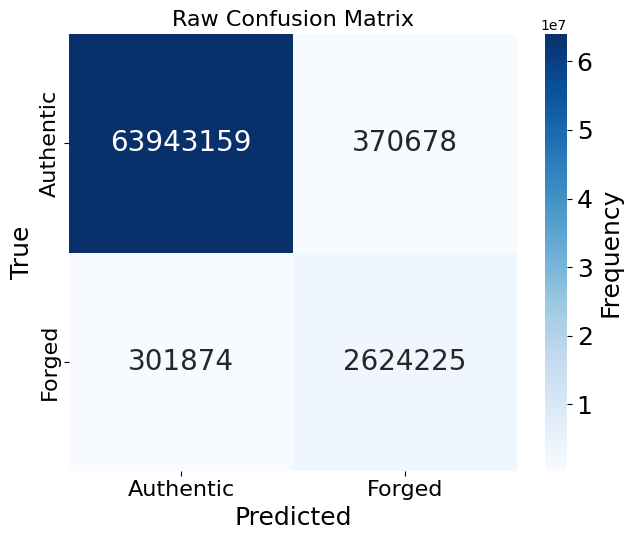

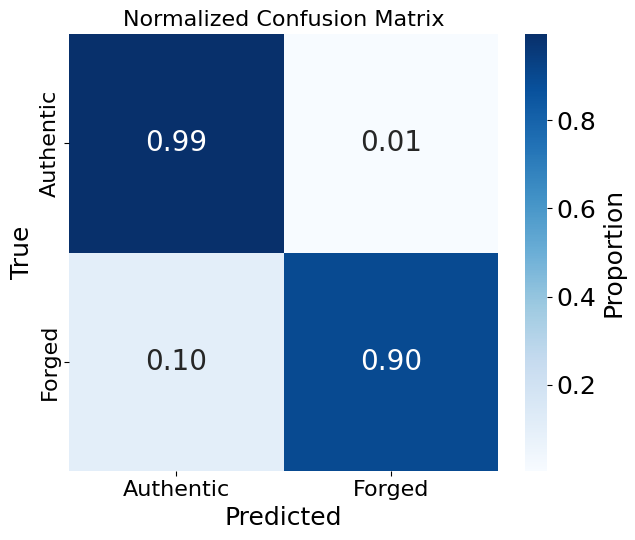

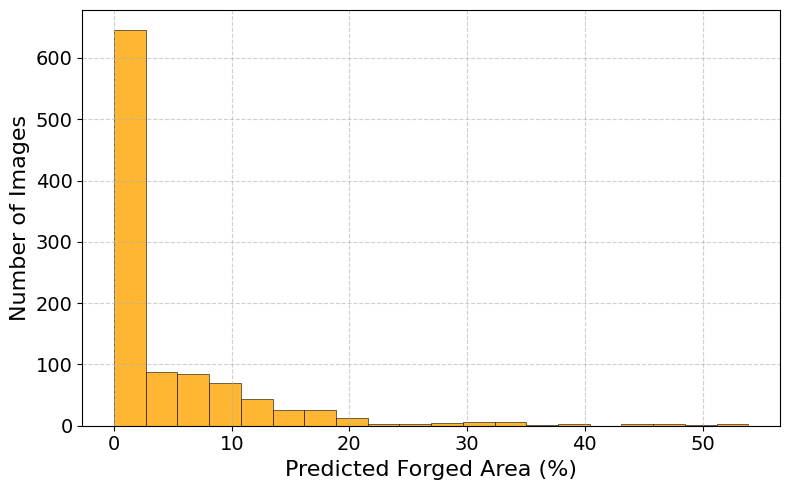


✅ EVALUATION COMPLETE — TEST SET RESULTS
Mean predicted forgery area: 4.45%
Localization IoU           : 0.6117
Centroid Error (px)        : 18.57

📁 Plots saved to          : /home/rab/Downloads/forgery_10_octiber_effi


In [ ]:
# ==============================================================
# CELL 2: MODEL EVALUATION ON THE EXACT TEST SUBSET
# ==============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp

# -----------------------------
# Configuration
# -----------------------------
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2

OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_SAVE_PATH = "/home/rab/Downloads/forgery_10_octiber_effi/effinet_model.pth"
DEVICE = torch.device("cpu")  # Using CPU to bypass any shared VRAM limits

# Build DataLoader using the test_idx from Cell 1
test_subset = Subset(dataset, test_idx)
test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# -----------------------------
# Load Model Weights
# -----------------------------
print("Loading trained model architecture and weights...")
model = smp.Unet(
    encoder_name="efficientnet-b0",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}.")

# -----------------------------
# Metric Helpers
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

# -----------------------------
# Inference + Metrics Collection
# -----------------------------
model.eval()

y_true_flat_all = []
y_pred_flat_all = []
stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc, centroid_errors, gt_area_pcts, pred_area_pcts, abs_area_errs = [], [], [], [], []
tcrs, fars = [], []
gt_pixel_counts, pred_pixel_counts, pred_area_fractions = [], [], []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test Inference"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            stats[cls]["tp"] += np.sum((pred_flat == cls) & (gt_flat == cls))
            stats[cls]["fp"] += np.sum((pred_flat == cls) & (gt_flat != cls))
            stats[cls]["fn"] += np.sum((pred_flat != cls) & (gt_flat == cls))
            stats[cls]["tn"] += np.sum((pred_flat != cls) & (gt_flat != cls))

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px, pred_px = int(gt.sum()), int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                tcrs.append(np.logical_and(pred == 1, gt == 1).sum() / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                fars.append(np.logical_and(pred == 1, gt == 0).sum() / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# Safe Relative Area Diff
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)
valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# Confusion Matrices & Plots
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm, annot=annot, fmt=fmt, cmap="Blues", cbar=True,
        xticklabels=["Authentic", "Forged"], yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)
    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()

save_cm_plot(cm_raw, "Raw Confusion Matrix", "cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "Normalized Confusion Matrix", "cm_norm.png", normalize=True)

# Histogram Plot
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "predicted_forgery_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()

# Aggregate Metrics
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# Results Summary
print("\n" + "="*80)
print("✅ EVALUATION COMPLETE — TEST SET RESULTS")
print("="*80)
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Localization IoU           : {loc_metrics['Localization IoU']:.4f}")
print(f"Centroid Error (px)        : {loc_metrics['Centroid Error (px)']:.2f}")
print(f"\n📁 Plots saved to          : {OUTPUT_DIR}")
print("="*80)

/tmp/ipykernel_12604/2988293759.py:58: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


⚠️ Running evaluation on: cpu
Loading trained model architecture and weights...
✅ Successfully loaded model weights from: /home/rab/Downloads/forgery_10_octiber_effi/effinet_model.pth
PREVIOUSLY SPLIT TEST DATASET IMAGE STATS
Total: 1026, Authentic: 475, Forged: 551


Inference & Metrics: 100%|███████████████████| 257/257 [00:18<00:00, 14.21it/s]


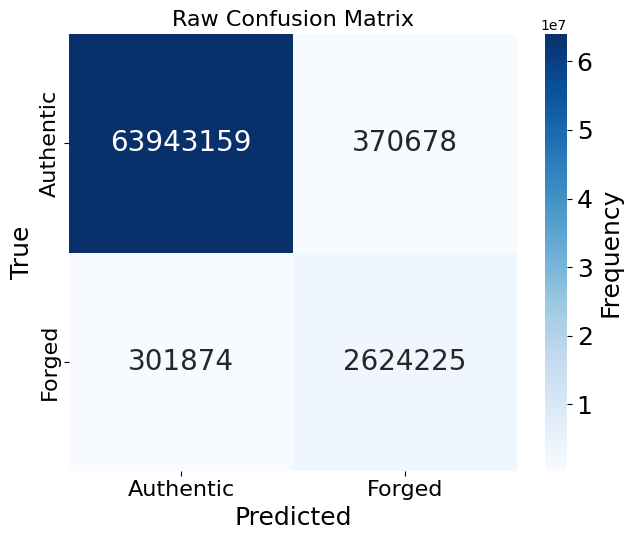

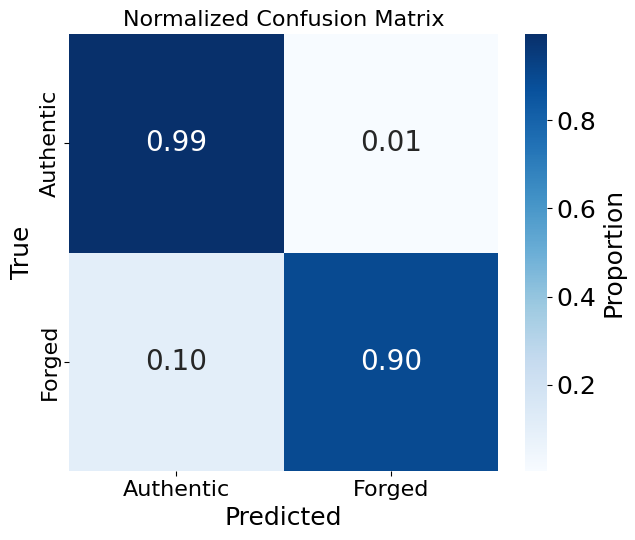

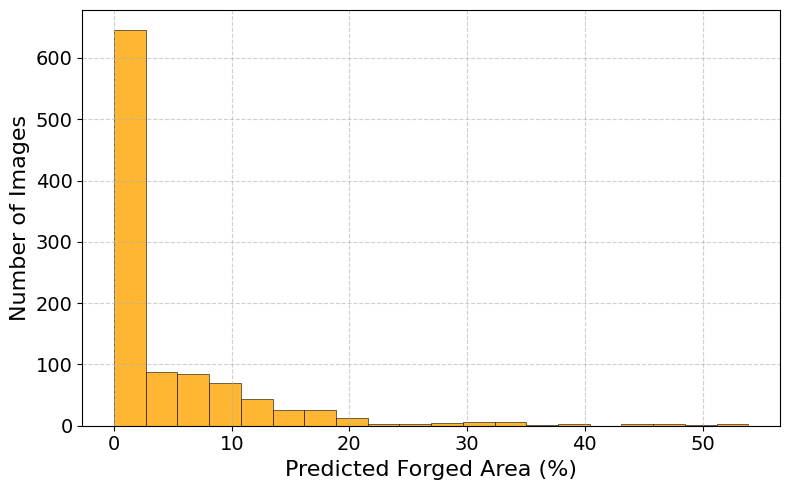


✅ EVALUATION COMPLETE — RESULTS
📊 PIXEL-LEVEL CLASSIFICATION METRICS
---------------------------------------------
Class        | Precision |    Recall |        F1
Authentic    |    0.9953 |    0.9942 |    0.9948
Forged       |    0.8762 |    0.8968 |    0.8864
Macro Avg    |    0.9358 |    0.9455 |    0.9406

🔍 CLASS-WISE ROBUST METRICS
---------------------------------------------

Authentic
  Dice           : 0.9948
  IoU            : 0.9896
  MCC            : 0.8812
  Hamming Loss   : 0.0100

Forged
  Dice           : 0.8864
  IoU            : 0.7960
  MCC            : 0.8812
  Hamming Loss   : 0.0100

Macro Average
  Dice           : 0.9406
  IoU            : 0.8928
  MCC            : 0.8812
  Hamming Loss   : 0.0100

📍 FORGERY LOCALIZATION METRICS
---------------------------------------------
Localization IoU              : 0.6117
Centroid Error (px)           : 18.57
Avg GT Forged Area (%)        : 4.3517
Avg Pred Forged Area (%)      : 4.4541
Abs Area Error (%)            : 0.

In [ ]:
# ============================================================
# COMPLETE FORGERY DETECTION EVALUATION (ON EXISTING TEST SPLIT)
# - Uses previously defined dataset, train_idx, and sequential test_idx
# - Evaluates on CPU to prevent OOM
# - Generates confusion matrices, metrics, and histograms
# ============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from collections import Counter
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp

# -----------------------------
# CONFIGURATION
# -----------------------------
TEST_FRACTION = 0.25
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2
RANDOM_STATE = 42

OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, "effinet_model.pth")

# 🔴 Force CPU for evaluation to bypass OOM errors from other processes
DEVICE = torch.device("cpu")
print(f"⚠️ Running evaluation on: {DEVICE}")

# -----------------------------
# RE-INITIALIZE & LOAD MODEL
# -----------------------------
print("Loading trained model architecture and weights...")
model = smp.Unet(
    encoder_name="efficientnet-b0",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}. Please run training first.")

# -----------------------------
# Helper: infer image class
# -----------------------------
def get_image_class(img_path):
    parts = Path(img_path).parts
    if "authentic" in parts:
        return 0
    elif "forged" in parts:
        return 1
    else:
        raise ValueError(f"Unknown class for {img_path}")

# Recreate the exact 25% test split from the train pool if not already in memory
if 'test_idx' not in globals():
    targets = [get_image_class(dataset.image_paths[i]) for i in range(len(dataset))]
    train_pool_idx, _ = train_test_split(
        list(range(len(dataset))),
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=targets
    )
    train_pool_targets = [targets[i] for i in train_pool_idx]
    _, test_idx = train_test_split(
        train_pool_idx,
        test_size=TEST_FRACTION,
        random_state=RANDOM_STATE,
        stratify=train_pool_targets
    )

test_subset = Subset(dataset, test_idx)
test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=False
)

# -----------------------------
# IMAGE-LEVEL STATS
# -----------------------------
subset_labels = [get_image_class(dataset.image_paths[i]) for i in test_idx]
print("=" * 80)
print("PREVIOUSLY SPLIT TEST DATASET IMAGE STATS")
print(f"Total: {len(subset_labels)}, Authentic: {Counter(subset_labels)[0]}, Forged: {Counter(subset_labels)[1]}")
print("=" * 80)

# -----------------------------
# METRIC HELPERS
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

# -----------------------------
# INFERENCE + METRICS COLLECTION
# -----------------------------
model.eval()

y_true_flat_all = []
y_pred_flat_all = []

stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc = []
centroid_errors = []
gt_area_pcts = []
pred_area_pcts = []
abs_area_errs = []
tcrs = []
fars = []

gt_pixel_counts = []
pred_pixel_counts = []
pred_area_fractions = []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Inference & Metrics"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            tp = np.sum((pred_flat == cls) & (gt_flat == cls))
            fp = np.sum((pred_flat == cls) & (gt_flat != cls))
            fn = np.sum((pred_flat != cls) & (gt_flat == cls))
            tn = np.sum((pred_flat != cls) & (gt_flat != cls))
            stats[cls]["tp"] += tp
            stats[cls]["fp"] += fp
            stats[cls]["fn"] += fn
            stats[cls]["tn"] += tn

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px = int(gt.sum())
            pred_px = int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                TP_reg = np.logical_and(pred == 1, gt == 1).sum()
                tcrs.append(TP_reg / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                FP_reg = np.logical_and(pred == 1, gt == 0).sum()
                fars.append(FP_reg / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# -----------------------------
# SAFE RELATIVE AREA DIFF
# -----------------------------
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)

valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) \
                     / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# -----------------------------
# CONFUSION MATRIX PLOTS
# -----------------------------
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm,
        annot=annot,
        fmt=fmt,
        cmap="Blues",
        cbar=True,
        xticklabels=["Authentic", "Forged"],
        yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)

    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()

save_cm_plot(cm_raw, "Raw Confusion Matrix", "cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "Normalized Confusion Matrix", "cm_norm.png", normalize=True)

# -----------------------------
# HISTOGRAM PLOT
# -----------------------------
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "predicted_forgery_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()

# -----------------------------
# AGGREGATE METRICS
# -----------------------------
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
prec_macro = precision_score(y_true_flat_all, y_pred_flat_all, average="macro")
rec_macro = recall_score(y_true_flat_all, y_pred_flat_all, average="macro")
f1_macro = f1_score(y_true_flat_all, y_pred_flat_all, average="macro")

class_results = {}
for cls, name in zip([0, 1], ["Authentic", "Forged"]):
    tp, fp, fn, tn = stats[cls]["tp"], stats[cls]["fp"], stats[cls]["fn"], stats[cls]["tn"]
    dice_val = dice_score(tp, fp, fn)
    iou_val = iou_score(tp, fp, fn)
    y_bin_true = (y_true_flat_all == cls).astype(int)
    y_bin_pred = (y_pred_flat_all == cls).astype(int)
    mcc_val = matthews_corrcoef(y_bin_true, y_bin_pred)
    hamming_val = hamming_loss(y_bin_true, y_bin_pred)
    class_results[name] = {
        "Dice": dice_val, "IoU": iou_val, "MCC": mcc_val, "Hamming Loss": hamming_val
    }

macro_avg = {
    m: np.nanmean([class_results["Authentic"][m], class_results["Forged"][m]])
    for m in ["Dice", "IoU", "MCC", "Hamming Loss"]
}
class_results["Macro Average"] = macro_avg

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# -----------------------------
# PRINT RESULTS
# -----------------------------
print("\n" + "="*80)
print("✅ EVALUATION COMPLETE — RESULTS")
print("="*80)

print("📊 PIXEL-LEVEL CLASSIFICATION METRICS")
print("-" * 45)
print(f"{'Class':12s} | {'Precision':>9s} | {'Recall':>9s} | {'F1':>9s}")
for i, name in enumerate(["Authentic", "Forged"]):
    print(f"{name:12s} | {prec[i]:9.4f} | {rec[i]:9.4f} | {f1[i]:9.4f}")
print(f"{'Macro Avg':12s} | {prec_macro:9.4f} | {rec_macro:9.4f} | {f1_macro:9.4f}")

print("\n🔍 CLASS-WISE ROBUST METRICS")
print("-" * 45)
for cls, vals in class_results.items():
    print(f"\n{cls}")
    for k, v in vals.items():
        print(f"  {k:15s}: {v:.4f}")

print("\n📍 FORGERY LOCALIZATION METRICS")
print("-" * 45)
for k, v in loc_metrics.items():
    if k == "Centroid Error (px)":
        print(f"{k:30s}: {v:.2f}" if not np.isnan(v) else f"{k:30s}: NaN")
    else:
        print(f"{k:30s}: {v:.4f}" if not np.isnan(v) else f"{k:30s}: NaN")

print("\n📈 PREDICTED FORGERY AREA (ALL IMAGES)")
print("-" * 45)
n_images = len(pred_area_percentages)
print(f"Total images evaluated     : {n_images}")
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Std deviation              : {pred_area_percentages.std():.2f}%")
print(f"Min / Max                  : {pred_area_percentages.min():.2f}% / {pred_area_percentages.max():.2f}%")
print(f"Median                     : {np.median(pred_area_percentages):.2f}%")

print("\n📁 Outputs saved to:")
print(f"    → {os.path.join(OUTPUT_DIR, 'cm_raw.png')}")
print(f"    → {os.path.join(OUTPUT_DIR, 'cm_norm.png')}")
print(f"    → {os.path.join(OUTPUT_DIR, 'predicted_forgery_area_hist.png')}")
print("="*80)

/tmp/ipykernel_12604/803438851.py:57: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


Loading trained model architecture and weights...
✅ Successfully loaded model weights from: /home/rab/Downloads/forgery_10_octiber_effi/effinet_model.pth


Test Inference: 100%|████████████████████████| 257/257 [00:17<00:00, 14.49it/s]


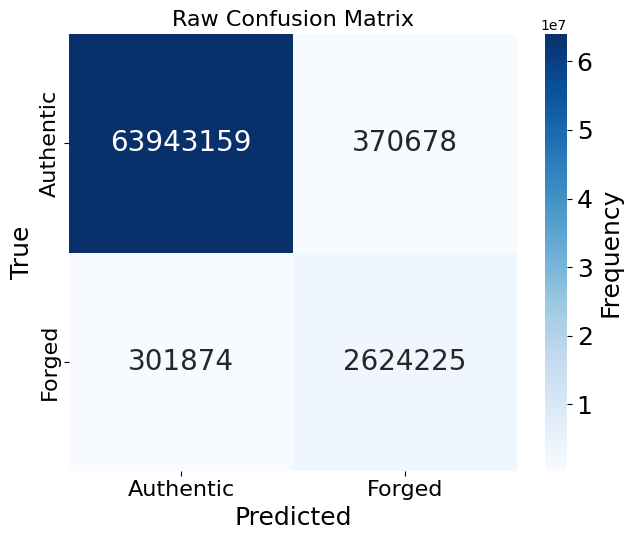

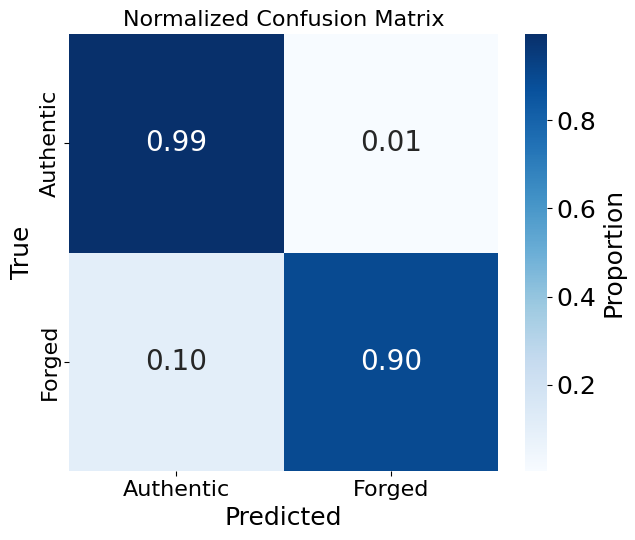

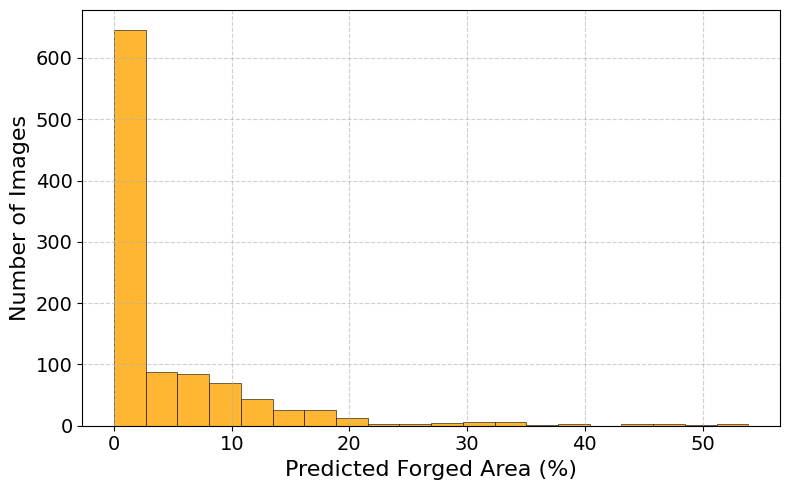


✅ EVALUATION COMPLETE — TEST SET RESULTS
Mean predicted forgery area: 4.45%
Localization IoU           : 0.6117
Centroid Error (px)        : 18.57

📁 Plots saved to          : /home/rab/Downloads/forgery_10_octiber_effi


In [ ]:
# ==============================================================
# CELL 2: MODEL EVALUATION ON THE EXACT TEST SUBSET
# ==============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp

# -----------------------------
# Configuration
# -----------------------------
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2

OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, "effinet_model.pth")
DEVICE = torch.device("cpu")  # Using CPU to bypass any shared VRAM limits

# Build DataLoader using the test_idx from Cell 1
test_subset = Subset(dataset, test_idx)
test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# -----------------------------
# Load Model Weights
# -----------------------------
print("Loading trained model architecture and weights...")
model = smp.Unet(
    encoder_name="efficientnet-b0",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}.")

# -----------------------------
# Metric Helpers
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

# -----------------------------
# Inference + Metrics Collection
# -----------------------------
model.eval()

y_true_flat_all = []
y_pred_flat_all = []
stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc, centroid_errors, gt_area_pcts, pred_area_pcts, abs_area_errs = [], [], [], [], []
tcrs, fars = [], []
gt_pixel_counts, pred_pixel_counts, pred_area_fractions = [], [], []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test Inference"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            stats[cls]["tp"] += np.sum((pred_flat == cls) & (gt_flat == cls))
            stats[cls]["fp"] += np.sum((pred_flat == cls) & (gt_flat != cls))
            stats[cls]["fn"] += np.sum((pred_flat != cls) & (gt_flat == cls))
            stats[cls]["tn"] += np.sum((pred_flat != cls) & (gt_flat != cls))

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px, pred_px = int(gt.sum()), int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                tcrs.append(np.logical_and(pred == 1, gt == 1).sum() / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                fars.append(np.logical_and(pred == 1, gt == 0).sum() / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# Safe Relative Area Diff
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)
valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# Confusion Matrices & Plots
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm, annot=annot, fmt=fmt, cmap="Blues", cbar=True,
        xticklabels=["Authentic", "Forged"], yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)
    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()

save_cm_plot(cm_raw, "Raw Confusion Matrix", "cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "Normalized Confusion Matrix", "cm_norm.png", normalize=True)

# Histogram Plot
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "predicted_forgery_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()

# Aggregate Metrics
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# Results Summary
print("\n" + "="*80)
print("✅ EVALUATION COMPLETE — TEST SET RESULTS")
print("="*80)
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Localization IoU           : {loc_metrics['Localization IoU']:.4f}")
print(f"Centroid Error (px)        : {loc_metrics['Centroid Error (px)']:.2f}")
print(f"\n📁 Plots saved to          : {OUTPUT_DIR}")
print("="*80)

/tmp/ipykernel_12604/674943914.py:138: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


⚠️ Running evaluation on: cpu
Loading dataset and recreating exact sequential split...
Loading trained model architecture and weights...
✅ Successfully loaded model weights from: /home/rab/Downloads/forgery_10_octiber_effi/effinet_model.pth

🔍 EVALUATING ON VALIDATION SET


Computing Class-wise Metrics: 100%|██████████| 257/257 [00:18<00:00, 14.14it/s]



Authentic
  Dice           : 0.9849
  IoU            : 0.9702
  MCC            : 0.6175
  Hamming Loss   : 0.0290

Forged
  Dice           : 0.6272
  IoU            : 0.4568
  MCC            : 0.6175
  Hamming Loss   : 0.0290

Macro Average
  Dice           : 0.8060
  IoU            : 0.7135
  MCC            : 0.6175
  Hamming Loss   : 0.0290

🔍 EVALUATING ON TEST SET (Localization, Centroids, Plots)


Test Set Inference: 100%|████████████████████| 257/257 [00:16<00:00, 16.05it/s]


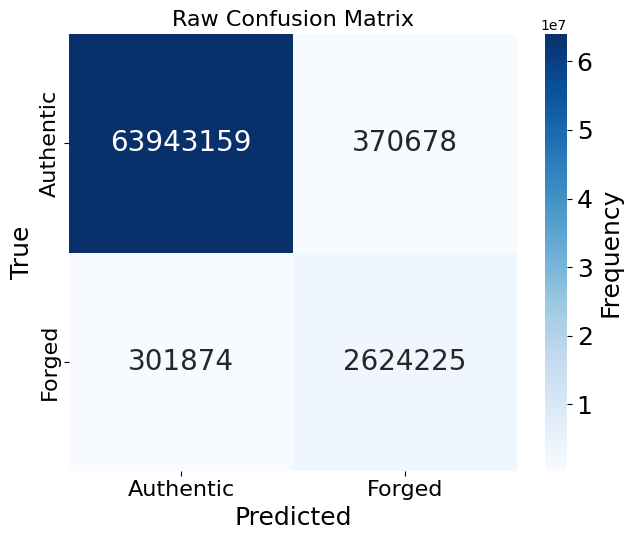

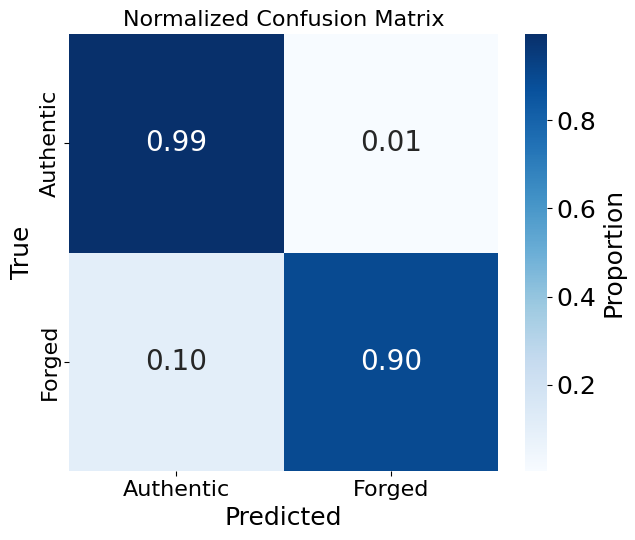

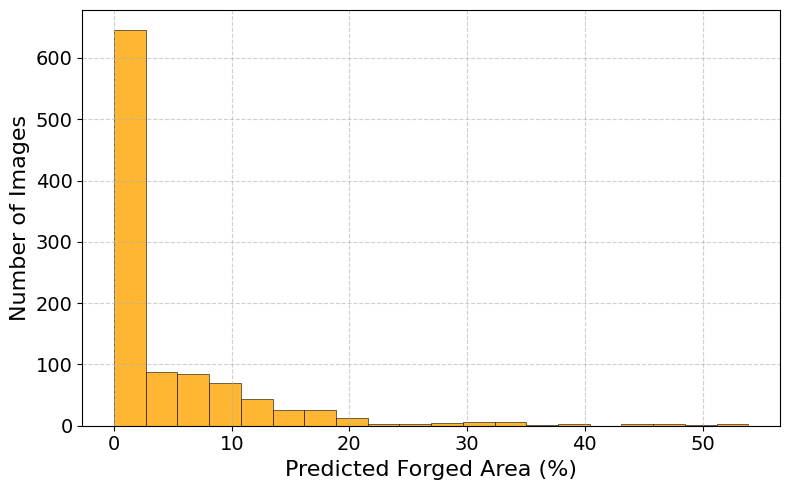


✅ TEST SET EVALUATION COMPLETE — RESULTS
Mean predicted forgery area: 4.45%
Localization IoU           : 0.6117
Centroid Error (px)        : 18.57

📁 Plots saved to          : /home/rab/Downloads/forgery_10_octiber_effi


In [ ]:
# ============================================================
# COMPLETE FORGERY DETECTION EVALUATION (CPU-SAFE & EXACT SPLIT)
# - Recreates exact sequential split (20% Val, 25% Test from Train)
# - Evaluates validation set and test set securely on CPU
# - Generates confusion matrices, histograms, and localization metrics
# ============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from collections import Counter
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp
import cv2


IMG_SIZE = (256, 256)
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2
RANDOM_STATE = 42

OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, "effinet_model.pth")

# 🔴 Force CPU for evaluation to bypass GPU OOM issues
DEVICE = torch.device("cpu")
print(f"⚠️ Running evaluation on: {DEVICE}")

# -----------------------------
# DATASET & EXACT SEQUENTIAL SPLIT
# -----------------------------
def find_mask_file(mask_dir, img_name):
    stem = Path(img_name).stem
    for p in [f"{stem}.npy", f"{stem}_mask.npy"]:
        path = os.path.join(mask_dir, p)
        if os.path.exists(path):
            return path
    for root, _, files in os.walk(mask_dir):
        for f in files:
            if Path(f).stem == stem:
                return os.path.join(root, f)
    return None

def load_mask_safe(mask_path, target_shape):
    if mask_path is None or not os.path.exists(mask_path):
        return np.zeros(target_shape, dtype=np.uint8)
    mask = np.squeeze(np.load(mask_path, allow_pickle=True))
    if mask.ndim > 2:
        mask = mask[..., 0]
    mask = (mask > 0.5).astype(np.uint8)
    if mask.shape != target_shape:
        mask = cv2.resize((mask * 255).astype(np.uint8), (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)
    return mask

class ForgerySegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, img_size=IMG_SIZE):
        self.img_size = img_size
        self.image_paths = []
        for folder in ["authentic", "forged"]:
            folder_path = Path(image_dir) / folder
            if folder_path.is_dir():
                for file in sorted(os.listdir(folder_path)):
                    if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                        self.image_paths.append(str(folder_path / file))
        self.mask_paths = [find_mask_file(mask_dir, Path(x).name) for x in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = cv2.imread(self.image_paths[index])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.img_size[1], self.img_size[0]))
        mask = load_mask_safe(self.mask_paths[index], (self.img_size[0], self.img_size[1]))
        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        mask = torch.from_numpy(mask).unsqueeze(0).float()
        return image, mask

def get_image_class_from_path(img_path):
    return 1 if "forged" in Path(img_path).parts else 0

print("Loading dataset and recreating exact sequential split...")
dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
targets = [get_image_class_from_path(p) for p in dataset.image_paths]

# Step 1: 20% validation set, 80% training pool
train_pool_idx, val_idx = train_test_split(
    list(range(len(dataset))),
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=targets
)

# Step 2: 25% test set from the training pool
train_pool_targets = [targets[i] for i in train_pool_idx]
train_idx, test_idx = train_test_split(
    train_pool_idx,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=train_pool_targets
)

val_subset = Subset(dataset, val_idx)
test_subset = Subset(dataset, test_idx)

val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# -----------------------------
# RE-INITIALIZE & LOAD MODEL
# -----------------------------
print("Loading trained model architecture and weights...")
model = smp.Unet(
    encoder_name="efficientnet-b0",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}. Please run training first.")

# -----------------------------
# METRIC HELPERS & REUSABLE FUNCTION
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

def compute_classwise_metrics(model, loader, device, threshold=0.5):
    model.eval()
    stats = {
        0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},
        1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},
    }
    y_true_all, y_pred_all = [], []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Computing Class-wise Metrics"):
            images = images.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.float32)

            logits = model(images)
            if logits.shape != masks.shape:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')

            probs = torch.sigmoid(logits)
            preds = (probs > threshold).long()
            gt = masks.long()

            gt_f = gt.view(-1).cpu().numpy()
            pred_f = preds.view(-1).cpu().numpy()

            y_true_all.append(gt_f)
            y_pred_all.append(pred_f)

            for cls in [0, 1]:
                tp = np.sum((pred_f == cls) & (gt_f == cls))
                fp = np.sum((pred_f == cls) & (gt_f != cls))
                fn = np.sum((pred_f != cls) & (gt_f == cls))
                tn = np.sum((pred_f != cls) & (gt_f != cls))

                stats[cls]["tp"] += tp
                stats[cls]["fp"] += fp
                stats[cls]["fn"] += fn
                stats[cls]["tn"] += tn

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    results = {}
    for cls, name in zip([0, 1], ["Authentic", "Forged"]):
        tp = stats[cls]["tp"]
        fp = stats[cls]["fp"]
        fn = stats[cls]["fn"]
        tn = stats[cls]["tn"]

        dice = dice_score(tp, fp, fn)
        iou = iou_score(tp, fp, fn)
        mcc = matthews_corrcoef((y_true_all == cls).astype(int), (y_pred_all == cls).astype(int))
        h_loss = hamming_loss((y_true_all == cls).astype(int), (y_pred_all == cls).astype(int))

        results[name] = {
            "Dice": dice,
            "IoU": iou,
            "MCC": mcc,
            "Hamming Loss": h_loss
        }

    results["Macro Average"] = {
        m: np.mean([results["Authentic"][m], results["Forged"][m]])
        for m in ["Dice", "IoU", "MCC", "Hamming Loss"]
    }
    return results, y_true_all, y_pred_all

# -----------------------------
# 1. VALIDATION SET EVALUATION
# -----------------------------
print("\n" + "="*80)
print("🔍 EVALUATING ON VALIDATION SET")
print("="*80)
val_metrics, _, _ = compute_classwise_metrics(model, val_loader, DEVICE, threshold=THRESHOLD)
for cls, vals in val_metrics.items():
    print(f"\n{cls}")
    for k, v in vals.items():
        print(f"  {k:15s}: {v:.4f}")

# -----------------------------
# 2. TEST SET DEEP EVALUATION & PLOTS
# -----------------------------
print("\n" + "="*80)
print("🔍 EVALUATING ON TEST SET (Localization, Centroids, Plots)")
print("="*80)

model.eval()
y_true_flat_all, y_pred_flat_all = [], []
stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc, centroid_errors, gt_area_pcts, pred_area_pcts, abs_area_errs = [], [], [], [], []
tcrs, fars = [], []
gt_pixel_counts, pred_pixel_counts, pred_area_fractions = [], [], []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test Set Inference"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            stats[cls]["tp"] += np.sum((pred_flat == cls) & (gt_flat == cls))
            stats[cls]["fp"] += np.sum((pred_flat == cls) & (gt_flat != cls))
            stats[cls]["fn"] += np.sum((pred_flat != cls) & (gt_flat == cls))
            stats[cls]["tn"] += np.sum((pred_flat != cls) & (gt_flat != cls))

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px, pred_px = int(gt.sum()), int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                tcrs.append(np.logical_and(pred == 1, gt == 1).sum() / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                fars.append(np.logical_and(pred == 1, gt == 0).sum() / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# Safe Relative Area Diff
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)
valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# Confusion Matrices & Plots
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm, annot=annot, fmt=fmt, cmap="Blues", cbar=True,
        xticklabels=["Authentic", "Forged"], yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)
    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()

save_cm_plot(cm_raw, "Raw Confusion Matrix", "cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "Normalized Confusion Matrix", "cm_norm.png", normalize=True)

# Histogram Plot
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "predicted_forgery_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()

# Aggregate Metrics
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
prec_macro = precision_score(y_true_flat_all, y_pred_flat_all, average="macro")
rec_macro = recall_score(y_true_flat_all, y_pred_flat_all, average="macro")
f1_macro = f1_score(y_true_flat_all, y_pred_flat_all, average="macro")

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# Print Test Results Summary
print("\n" + "="*80)
print("✅ TEST SET EVALUATION COMPLETE — RESULTS")
print("="*80)
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Localization IoU           : {loc_metrics['Localization IoU']:.4f}")
print(f"Centroid Error (px)        : {loc_metrics['Centroid Error (px)']:.2f}")
print(f"\n📁 Plots saved to          : {OUTPUT_DIR}")
print("="*80)

In [ ]:
# ============================================================
# EVALUATION ON PREVIOUSLY SPLIT TEST DATASET
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import matthews_corrcoef, hamming_loss
from tqdm import tqdm

# -----------------------------
# Dice and IoU helper functions
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

# -----------------------------
# Compute class-wise metrics
# -----------------------------
def compute_classwise_metrics(model, loader, device, threshold=0.5):
    model.eval()

    # Accumulators for each class
    stats = {
        0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},  # Authentic
        1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},  # Forged
    }

    y_true_all = []
    y_pred_all = []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Computing Class-wise Metrics"):
            images = images.to(device, dtype=torch.float32)
            masks  = masks.to(device, dtype=torch.float32)

            logits = model(images)
            if logits.shape != masks.shape:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')

            probs = torch.sigmoid(logits)
            preds = (probs > threshold).long()
            gt = masks.long()

            # Flatten
            gt_f   = gt.view(-1).cpu().numpy()
            pred_f = preds.view(-1).cpu().numpy()

            y_true_all.append(gt_f)
            y_pred_all.append(pred_f)

            for cls in [0, 1]:
                tp = np.sum((pred_f == cls) & (gt_f == cls))
                fp = np.sum((pred_f == cls) & (gt_f != cls))
                fn = np.sum((pred_f != cls) & (gt_f == cls))
                tn = np.sum((pred_f != cls) & (gt_f != cls))

                stats[cls]["tp"] += tp
                stats[cls]["fp"] += fp
                stats[cls]["fn"] += fn
                stats[cls]["tn"] += tn

    # Concatenate for MCC & Hamming
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    results = {}

    for cls, name in zip([0, 1], ["Authentic", "Forged"]):
        tp = stats[cls]["tp"]
        fp = stats[cls]["fp"]
        fn = stats[cls]["fn"]
        tn = stats[cls]["tn"]

        dice = dice_score(tp, fp, fn)
        iou  = iou_score(tp, fp, fn)

        # MCC (binary per class)
        mcc = matthews_corrcoef(
            (y_true_all == cls).astype(int),
            (y_pred_all == cls).astype(int)
        )

        # Hamming loss
        h_loss = hamming_loss(
            (y_true_all == cls).astype(int),
            (y_pred_all == cls).astype(int)
        )

        results[name] = {
            "Dice": dice,
            "IoU": iou,
            "MCC": mcc,
            "Hamming Loss": h_loss
        }

    # Combined (macro average)
    results["Macro Average"] = {
        m: np.mean([results["Authentic"][m], results["Forged"][m]])
        for m in ["Dice", "IoU", "MCC", "Hamming Loss"]
    }

    return results

# -----------------------------
# Execute class-wise metrics on test_loader
# -----------------------------
# Note: Using DEVICE and test_loader from your environment
metrics = compute_classwise_metrics(model, test_loader, DEVICE, threshold=0.5)

# -----------------------------
# Print results
# -----------------------------
print("\n" + "="*50)
print("✅ CLASS-WISE TEST METRICS")
print("="*50)
for cls, vals in metrics.items():
    print(f"\n{cls}")
    for k, v in vals.items():
        print(f"  {k:15s}: {v:.4f}")
print("="*50)

Computing Class-wise Metrics: 100%|██████████| 257/257 [00:16<00:00, 15.88it/s]



✅ CLASS-WISE TEST METRICS

Authentic
  Dice           : 0.9948
  IoU            : 0.9896
  MCC            : 0.8812
  Hamming Loss   : 0.0100

Forged
  Dice           : 0.8864
  IoU            : 0.7960
  MCC            : 0.8812
  Hamming Loss   : 0.0100

Macro Average
  Dice           : 0.9406
  IoU            : 0.8928
  MCC            : 0.8812
  Hamming Loss   : 0.0100


In [ ]:
# ============================================================
# EVALUATION ON PREVIOUSLY SPLIT TEST DATASET
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
from sklearn.metrics import matthews_corrcoef, hamming_loss
from tqdm import tqdm

# -----------------------------
# Dice and IoU helper functions
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

# -----------------------------
# Compute class-wise metrics
# -----------------------------
def compute_classwise_metrics(model, loader, device, threshold=0.5):
    model.eval()

    # Accumulators for each class
    stats = {
        0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},  # Authentic
        1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},  # Forged
    }

    y_true_all = []
    y_pred_all = []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Computing Class-wise Metrics"):
            images = images.to(device, dtype=torch.float32)
            masks  = masks.to(device, dtype=torch.float32)

            logits = model(images)
            if logits.shape != masks.shape:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')

            probs = torch.sigmoid(logits)
            preds = (probs > threshold).long()
            gt = masks.long()

            # Flatten
            gt_f   = gt.view(-1).cpu().numpy()
            pred_f = preds.view(-1).cpu().numpy()

            y_true_all.append(gt_f)
            y_pred_all.append(pred_f)

            for cls in [0, 1]:
                tp = np.sum((pred_f == cls) & (gt_f == cls))
                fp = np.sum((pred_f == cls) & (gt_f != cls))
                fn = np.sum((pred_f != cls) & (gt_f == cls))
                tn = np.sum((pred_f != cls) & (gt_f != cls))

                stats[cls]["tp"] += tp
                stats[cls]["fp"] += fp
                stats[cls]["fn"] += fn
                stats[cls]["tn"] += tn

    # Concatenate for MCC & Hamming
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    results = {}

    for cls, name in zip([0, 1], ["Authentic", "Forged"]):
        tp = stats[cls]["tp"]
        fp = stats[cls]["fp"]
        fn = stats[cls]["fn"]
        tn = stats[cls]["tn"]

        dice = dice_score(tp, fp, fn)
        iou  = iou_score(tp, fp, fn)

        # MCC (binary per class)
        mcc = matthews_corrcoef(
            (y_true_all == cls).astype(int),
            (y_pred_all == cls).astype(int)
        )

        # Hamming loss
        h_loss = hamming_loss(
            (y_true_all == cls).astype(int),
            (y_pred_all == cls).astype(int)
        )

        results[name] = {
            "Dice": dice,
            "IoU": iou,
            "MCC": mcc,
            "Hamming Loss": h_loss
        }

    # Combined (macro average)
    results["Macro Average"] = {
        m: np.mean([results["Authentic"][m], results["Forged"][m]])
        for m in ["Dice", "IoU", "MCC", "Hamming Loss"]
    }

    return results

# -----------------------------
# Execute class-wise metrics on test_loader
# -----------------------------
# Note: Using DEVICE and test_loader from your environment
metrics = compute_classwise_metrics(model, test_loader, DEVICE, threshold=0.5)

# -----------------------------
# Print results
# -----------------------------
print("\n" + "="*50)
print("✅ CLASS-WISE TEST METRICS")
print("="*50)
for cls, vals in metrics.items():
    print(f"\n{cls}")
    for k, v in vals.items():
        print(f"  {k:15s}: {v:.4f}")
print("="*50)

Computing Class-wise Metrics: 100%|██████████| 257/257 [00:16<00:00, 15.74it/s]



✅ CLASS-WISE TEST METRICS

Authentic
  Dice           : 0.9948
  IoU            : 0.9896
  MCC            : 0.8812
  Hamming Loss   : 0.0100

Forged
  Dice           : 0.8864
  IoU            : 0.7960
  MCC            : 0.8812
  Hamming Loss   : 0.0100

Macro Average
  Dice           : 0.9406
  IoU            : 0.8928
  MCC            : 0.8812
  Hamming Loss   : 0.0100


/home/rab/gpu_env/lib/python3.10/site-packages/torch/nn/modules/module.py:1827: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


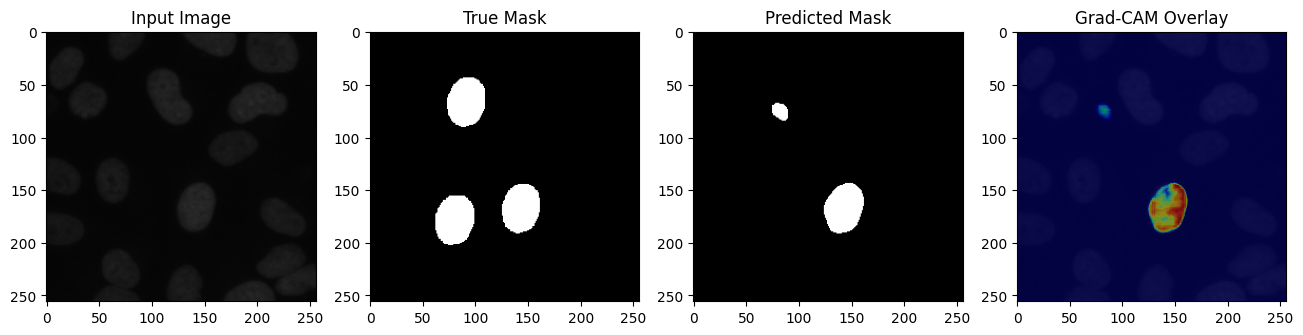

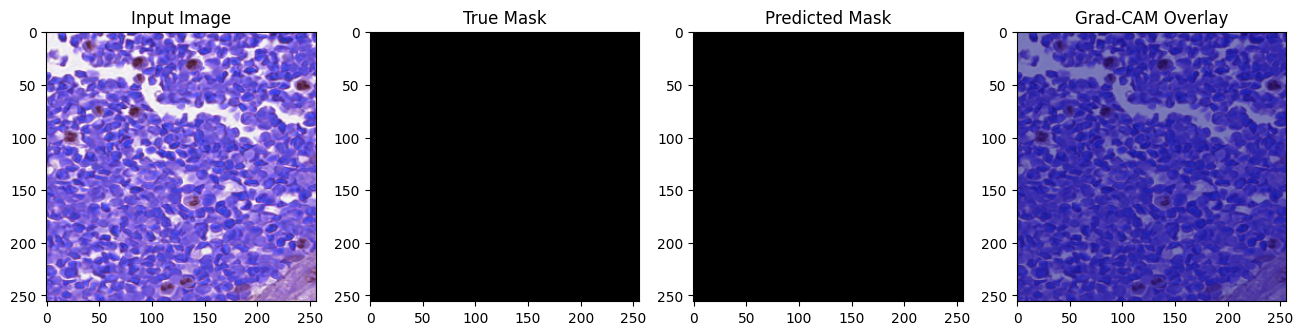

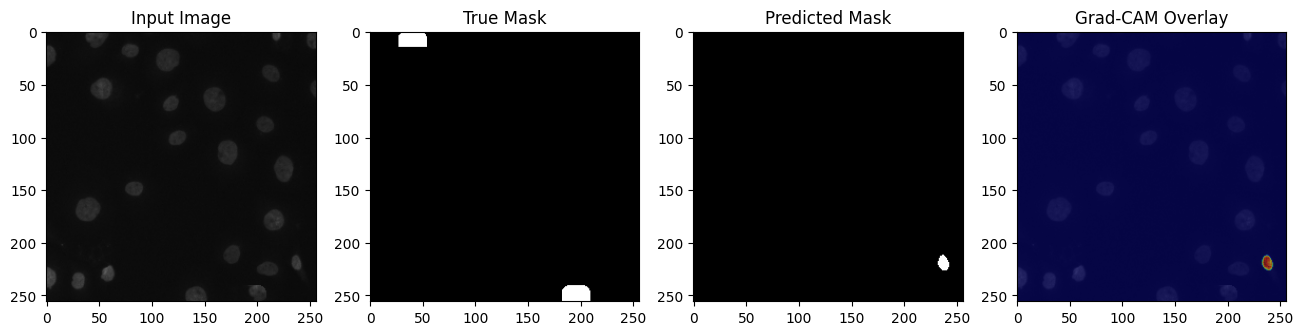

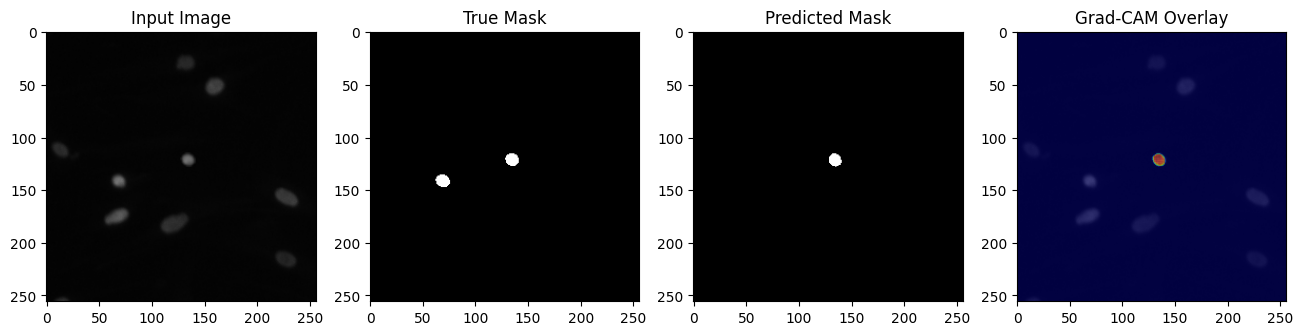

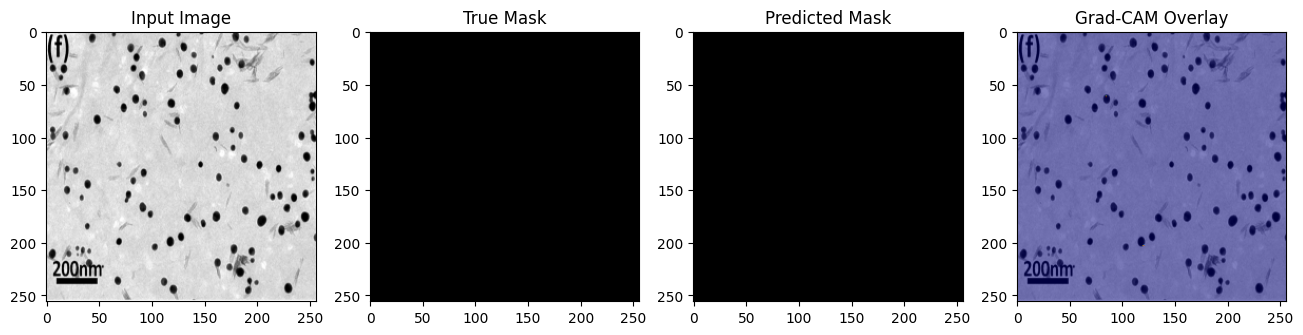

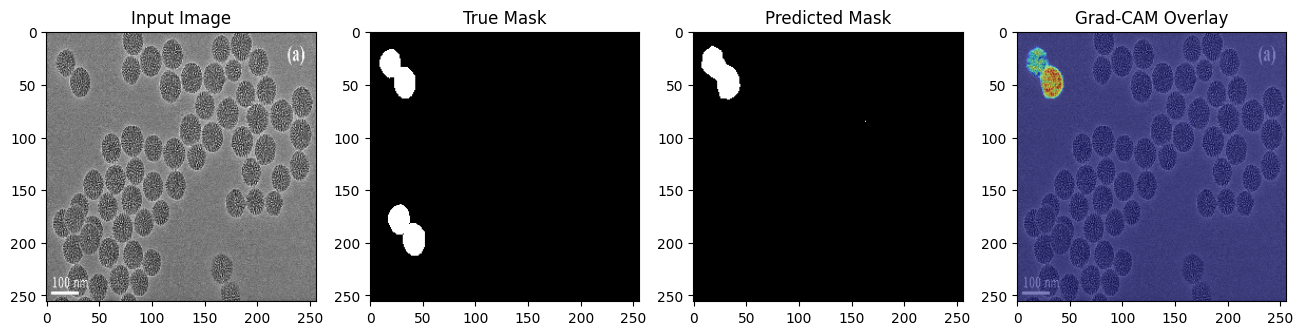

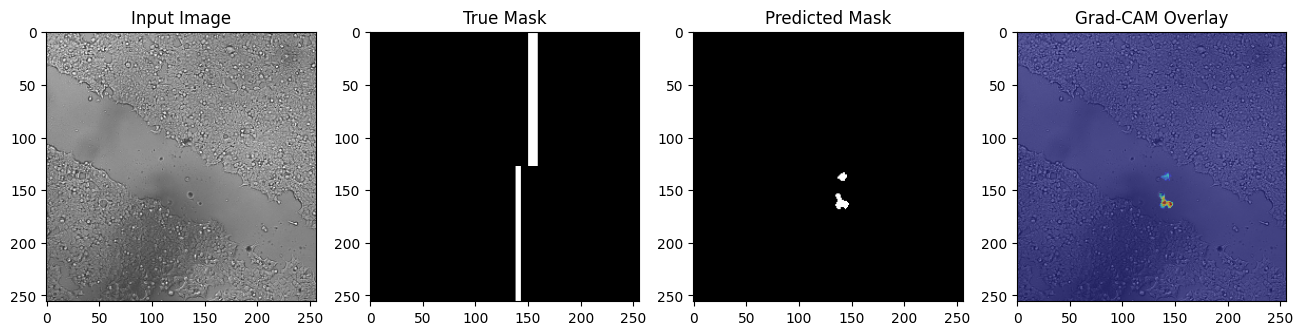

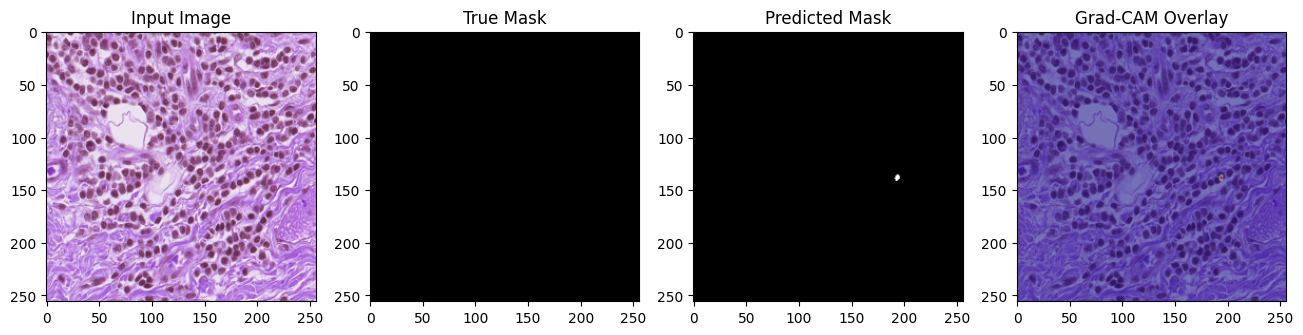

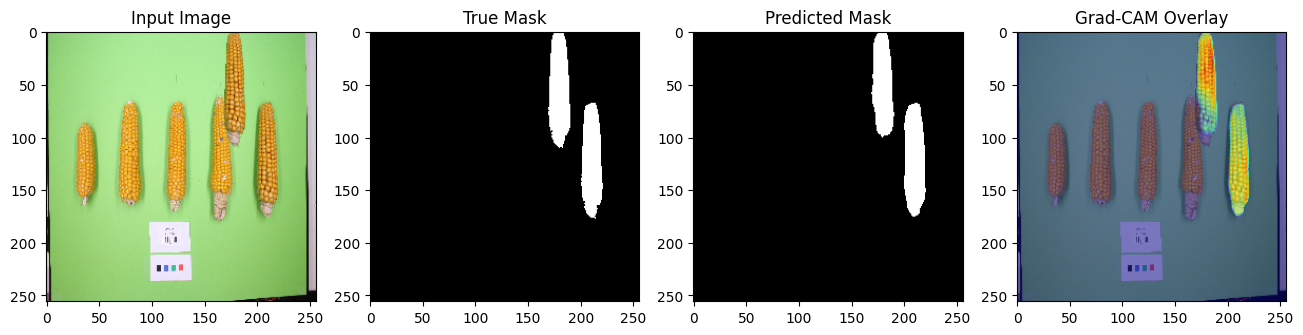

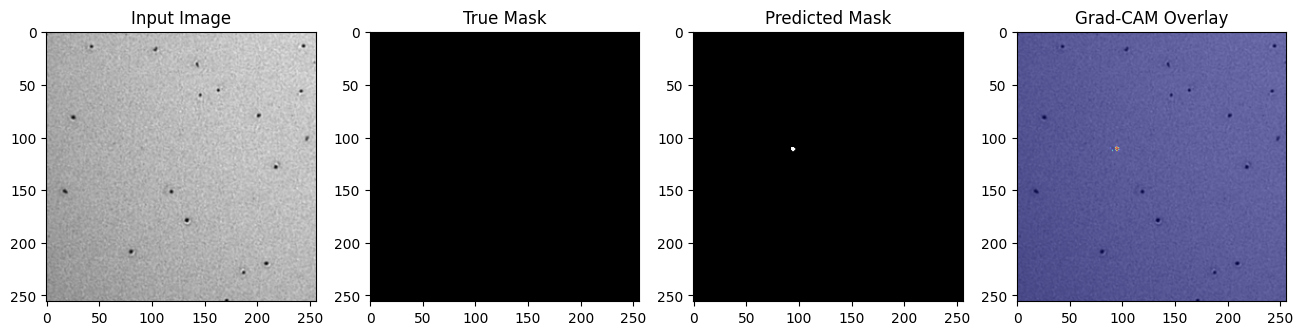

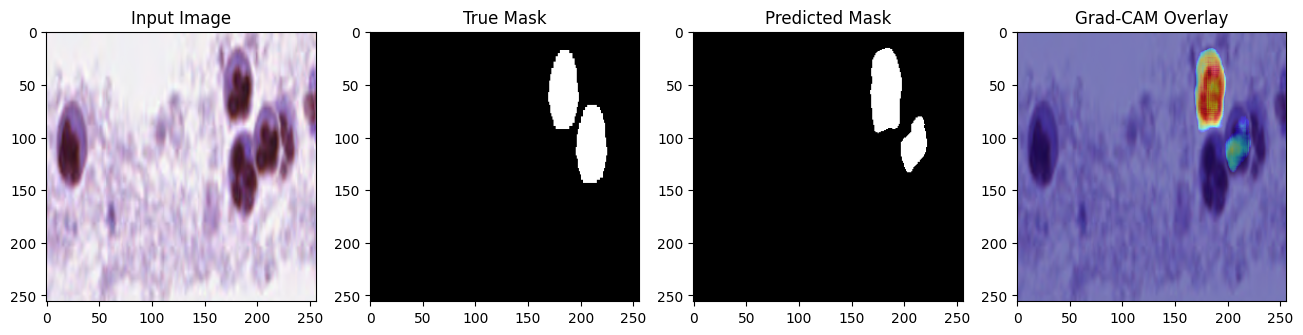

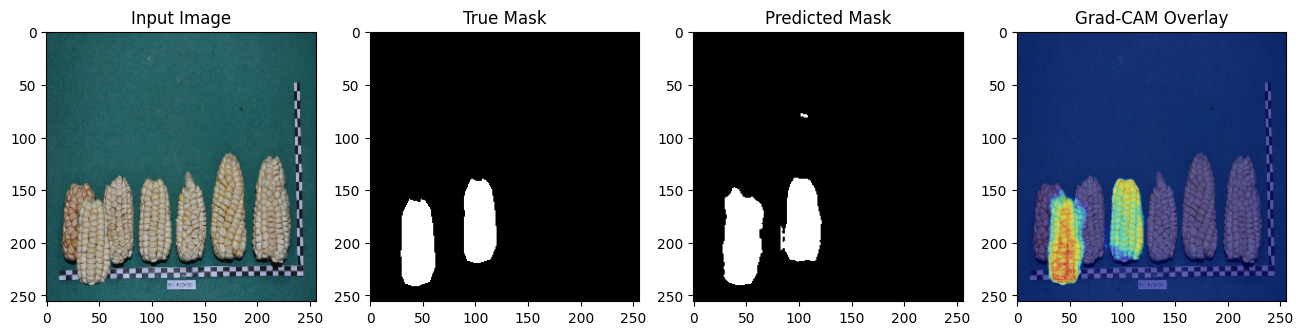

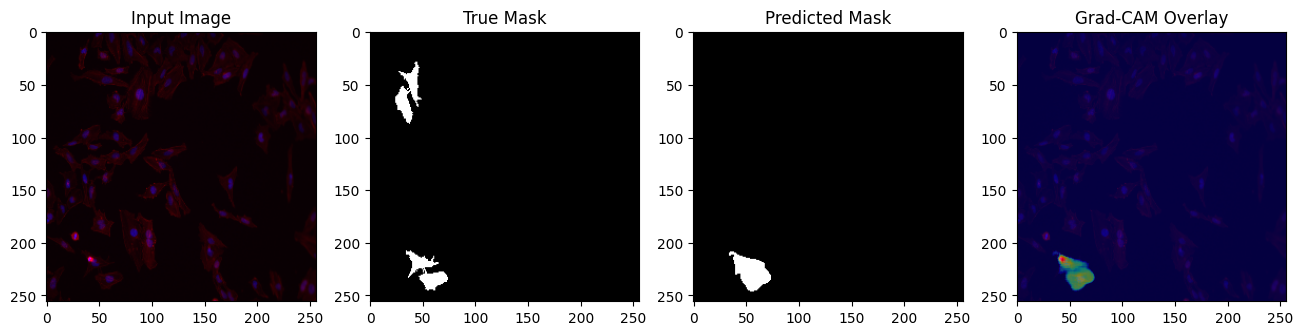

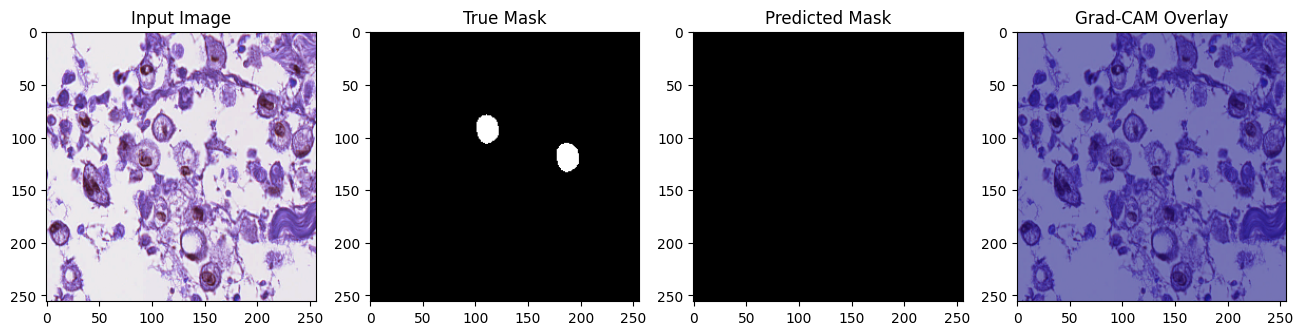

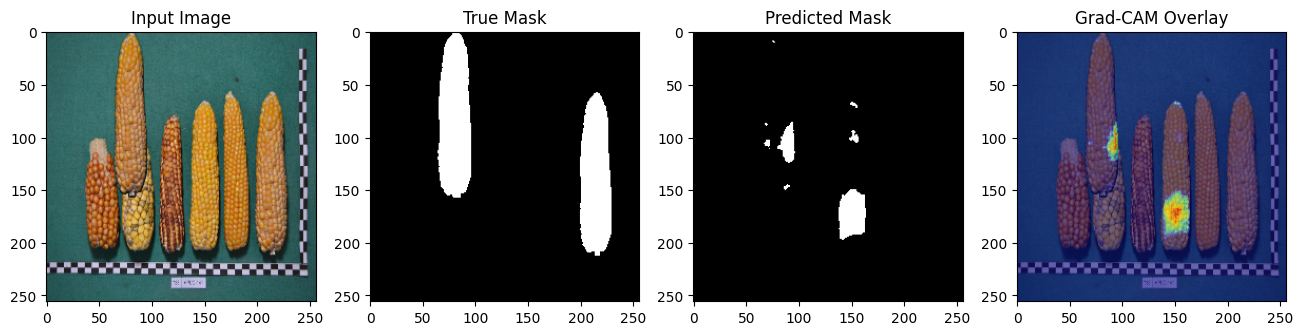

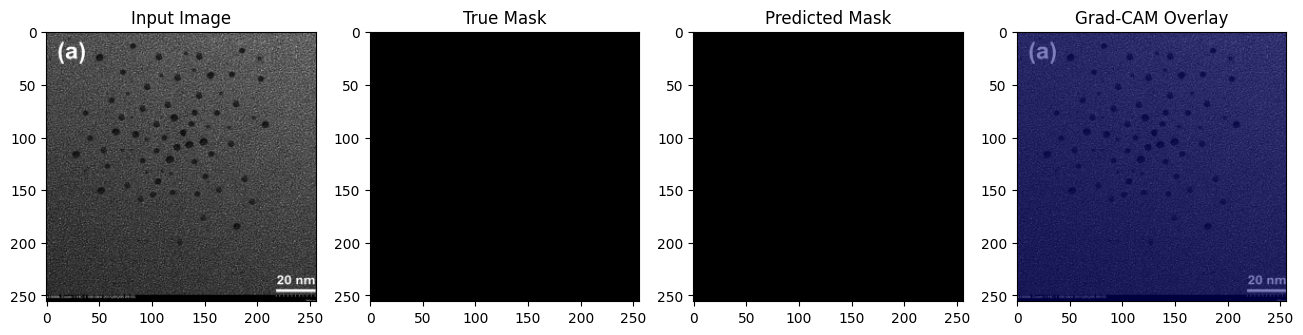

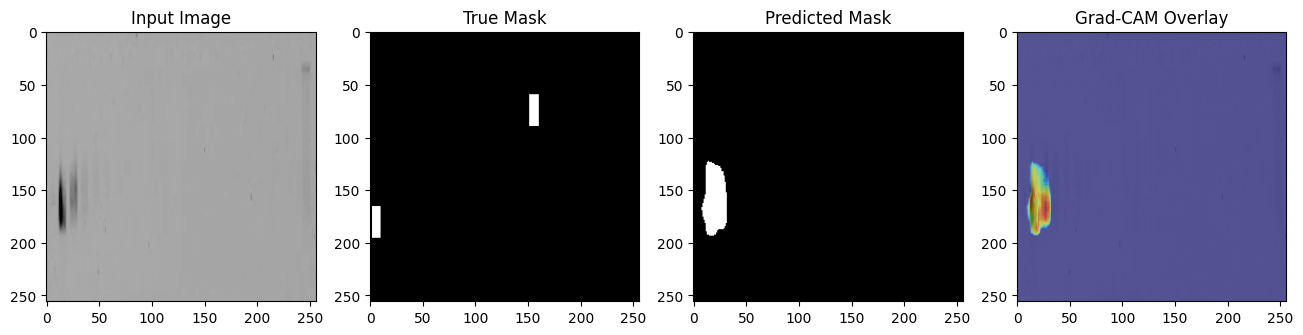

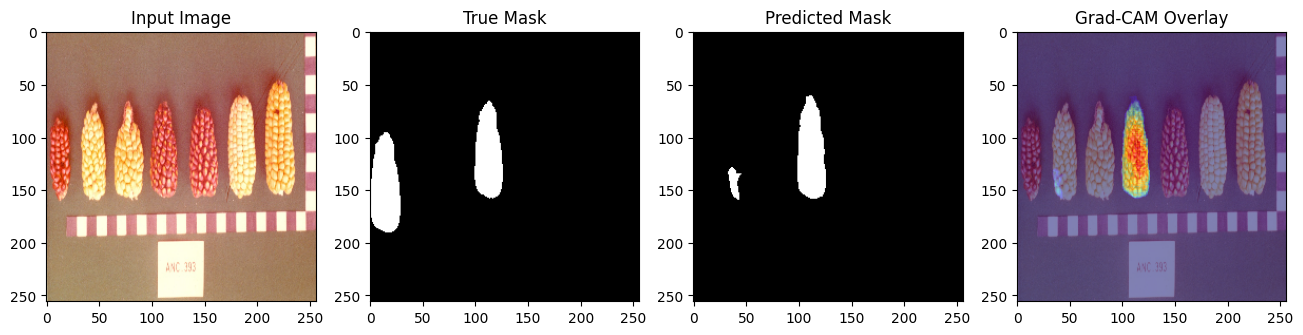

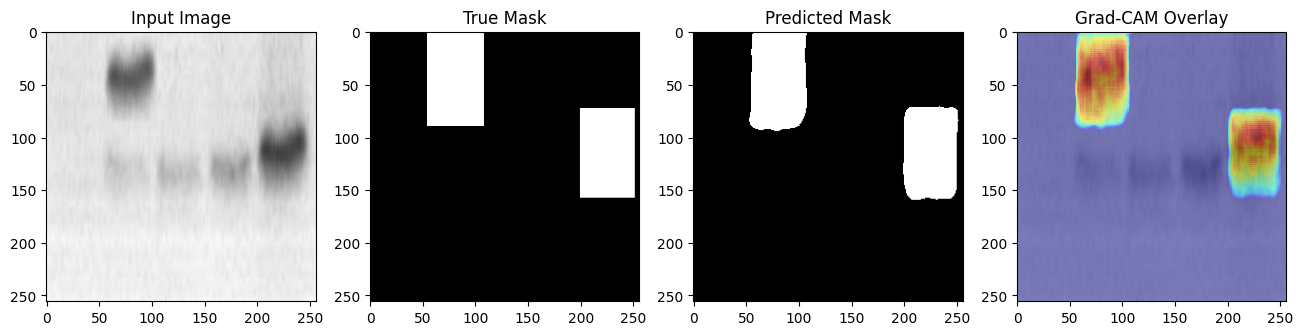

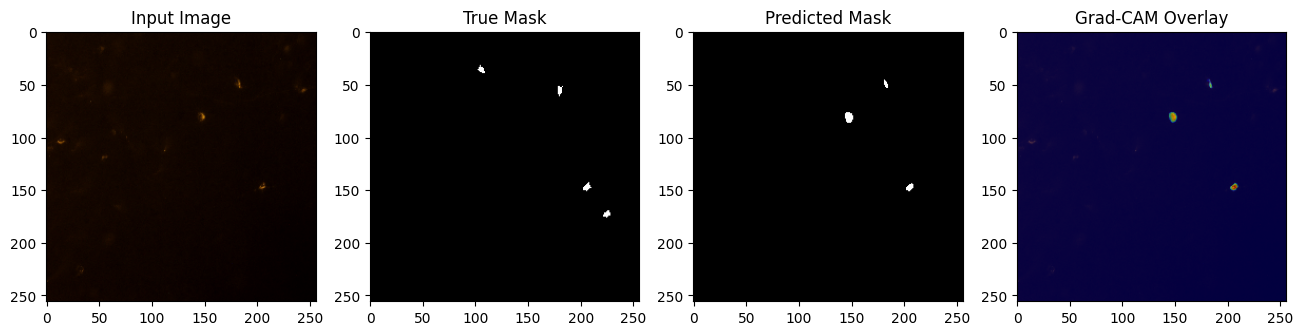

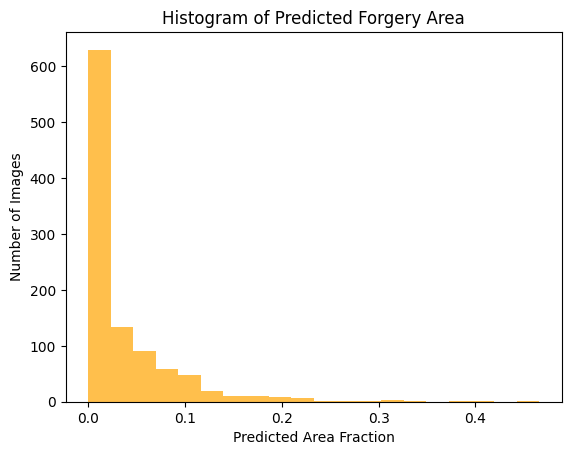

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random

# -----------------------------
# Grad-CAM for UNet
# -----------------------------
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.grad = None
        self.act = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, inp, out):
            self.act = out.detach()
        def backward_hook(module, grad_in, grad_out):
            self.grad = grad_out[0].detach()
        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate(self, x):
        self.model.zero_grad()
        logits = self.model(x)
        if logits.shape[2:] != x.shape[2:]:
            logits = F.interpolate(logits, size=x.shape[2:], mode='bilinear', align_corners=False)
        out = logits.sum()
        out.backward()
        w = self.grad.mean(dim=(2,3), keepdim=True)
        cam = F.relu((w * self.act).sum(dim=1, keepdim=True))
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam

# -----------------------------
# Random sampling from loader
# -----------------------------
def get_random_batch(loader, device, n=20):
    all_images, all_masks = [], []
    # Gather all batches
    for images, masks in loader:
        all_images.append(images)
        all_masks.append(masks)
    images_full = torch.cat(all_images, dim=0)
    masks_full = torch.cat(all_masks, dim=0)

    total = images_full.size(0)
    idxs = random.sample(range(total), min(n, total))
    return images_full[idxs].to(device), masks_full[idxs].to(device)

# -----------------------------
# Visualize Grad-CAM + mask
# -----------------------------
def visualize_gradcam_random(model, loader, device, n=20):
    model.eval()
    images, masks = get_random_batch(loader, device, n)

    # Select target layer: last conv layer of decoder (adjust according to your UNet)
    target_layer = model.decoder.blocks[-1].conv2  # for smp.Unet
    cam_gen = GradCAM(model, target_layer)

    with torch.no_grad():
        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).float()

    cams = cam_gen.generate(images)

    images_np = images.cpu().numpy().transpose(0,2,3,1)
    masks_np = masks.cpu().numpy()
    preds_np = preds.cpu().numpy()
    cams_np = cams.detach().cpu().numpy()

    for i in range(images_np.shape[0]):
        fig, ax = plt.subplots(1,4, figsize=(16,4))
        ax[0].imshow(images_np[i])
        ax[0].set_title("Input Image")
        ax[1].imshow(masks_np[i][0], cmap='gray')
        ax[1].set_title("True Mask")
        ax[2].imshow(preds_np[i][0], cmap='gray')
        ax[2].set_title("Predicted Mask")
        ax[3].imshow(images_np[i])
        ax[3].imshow(cams_np[i][0], cmap='jet', alpha=0.5)
        ax[3].set_title("Grad-CAM Overlay")
        for a in ax: a.axis("on")
        plt.show()

# -----------------------------
# Optional: Compute area fraction of predicted masks
# -----------------------------
def compute_pred_area(loader, model, device):
    model.eval()
    areas = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            logits = model(images)
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).float()
            frac = preds.view(preds.size(0), -1).sum(dim=1) / (preds.size(2)*preds.size(3))
            areas.extend(frac.cpu().numpy())
    return areas

# -----------------------------
# Run visualizations for 20 random images
# -----------------------------
visualize_gradcam_random(model, val_loader, DEVICE, n=20)

# -----------------------------
# Area fraction histogram
# -----------------------------
areas = compute_pred_area(val_loader, model, DEVICE)
plt.hist(areas, bins=20, color='orange', alpha=0.7)
plt.xlabel("Predicted Area Fraction")
plt.ylabel("Number of Images")
plt.title("Histogram of Predicted Forgery Area")
plt.show()

In [ ]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# -----------------------------
# Grad-CAM for UNet
# -----------------------------
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.grad = None
        self.act = None
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, inp, out):
            self.act = out.detach()
        def backward_hook(module, grad_in, grad_out):
            self.grad = grad_out[0].detach()
        self.target_layer.register_forward_hook(forward_hook)
        self.target_layer.register_backward_hook(backward_hook)

    def generate(self, x):
        self.model.zero_grad()
        logits = self.model(x)
        if logits.shape[2:] != x.shape[2:]:
            # Resize logits to input image size
            logits = F.interpolate(logits, size=x.shape[2:], mode='bilinear', align_corners=False)
        # Use sum over all pixels as scalar output
        out = logits.sum()
        out.backward()
        w = self.grad.mean(dim=(2,3), keepdim=True)
        cam = F.relu((w * self.act).sum(dim=1, keepdim=True))
        # Normalize between 0-1
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam

# -----------------------------
# Visualize Grad-CAM + mask
# -----------------------------
def visualize_gradcam(model, loader, device, n=4):
    model.eval()
    images, masks = next(iter(loader))
    images = images.to(device)
    masks = masks.to(device)

    # Select target layer: last conv layer of decoder
    target_layer = model.decoder.blocks[-1].conv2  # for UNet
    cam_gen = GradCAM(model, target_layer)

    with torch.no_grad():
        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).float()

    # Generate Grad-CAM for first n images
    cams = cam_gen.generate(images[:n])

    images_np = images.cpu().numpy().transpose(0,2,3,1)
    masks_np = masks.cpu().numpy()
    preds_np = preds.cpu().numpy()
    cams_np = cams.cpu().numpy()

    for i in range(n):
        fig, ax = plt.subplots(1,4, figsize=(16,4))
        ax[0].imshow(images_np[i])
        ax[0].set_title("Input Image")
        ax[1].imshow(masks_np[i][0], cmap='gray')
        ax[1].set_title("True Mask")
        ax[2].imshow(preds_np[i][0], cmap='gray')
        ax[2].set_title("Predicted Mask")
        ax[3].imshow(images_np[i])
        ax[3].imshow(cams_np[i][0], cmap='jet', alpha=0.5)
        ax[3].set_title("Grad-CAM Overlay")
        for a in ax: a.axis("off")
        plt.show()

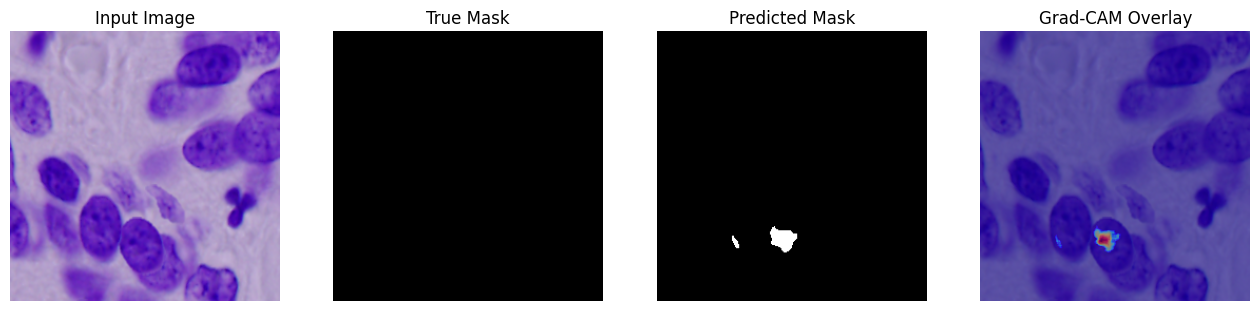

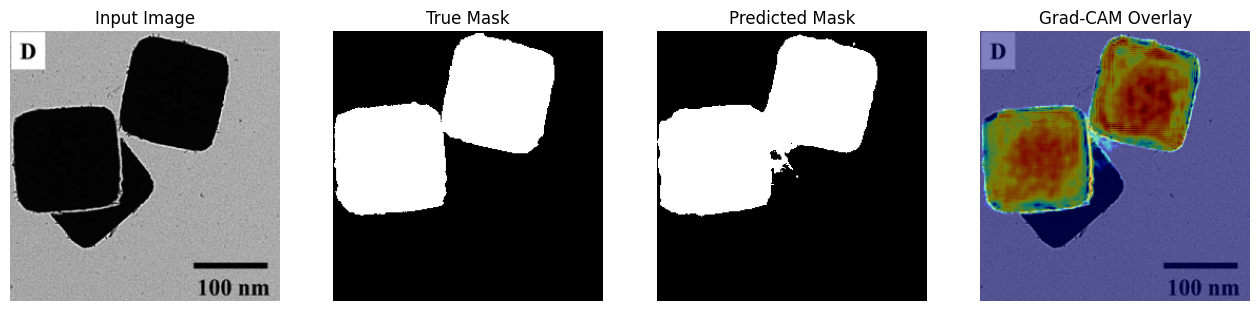

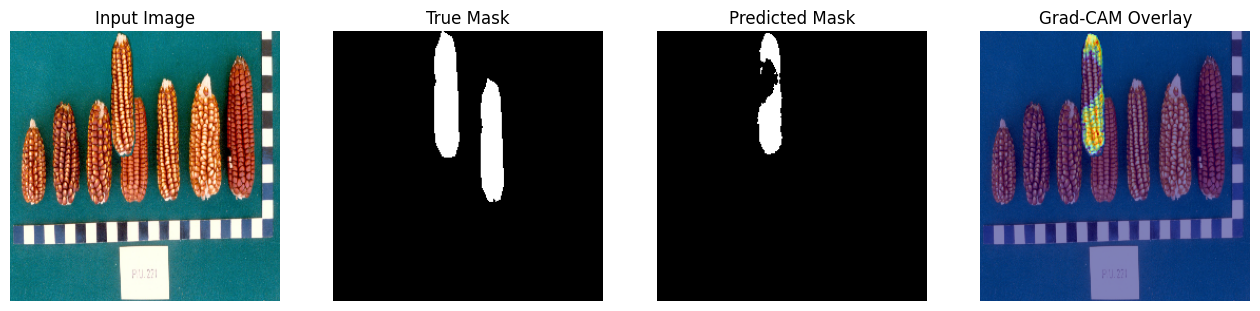

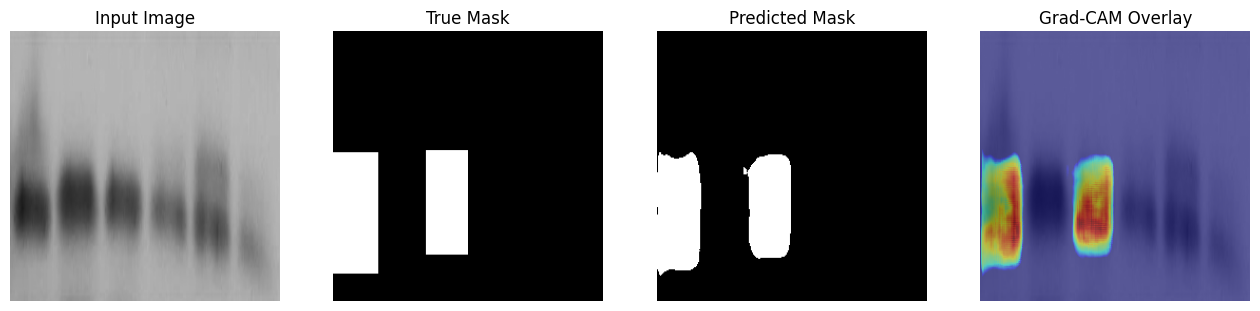

Predicted forgery area fraction (first 10 images): [np.float32(0.0067596436), np.float32(0.30366516), np.float32(0.024627686), np.float32(0.1239624), np.float32(0.0395813), np.float32(0.014404297), np.float32(0.015960693), np.float32(0.0048217773), np.float32(0.077056885), np.float32(0.016281128)]


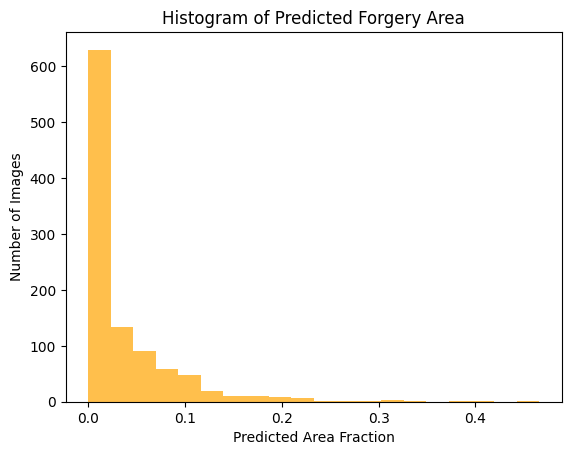

In [ ]:
# -----------------------------
# Visualize Grad-CAM + predicted masks
# -----------------------------
visualize_gradcam(model, val_loader, DEVICE, n=4)

# -----------------------------
# Optional: Compute area fraction of predicted masks
# -----------------------------
def compute_pred_area(loader, model, device):
    model.eval()
    areas = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            logits = model(images)
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).float()
            # Fraction of pixels predicted as forgery
            frac = preds.view(preds.size(0), -1).sum(dim=1) / (preds.size(2)*preds.size(3))
            areas.extend(frac.cpu().numpy())
    return areas

# Call area computation
areas = compute_pred_area(val_loader, model, DEVICE)
print("Predicted forgery area fraction (first 10 images):", areas[:10])

# Optional: plot histogram of predicted areas
plt.hist(areas, bins=20, color='orange', alpha=0.7)
plt.xlabel("Predicted Area Fraction")
plt.ylabel("Number of Images")
plt.title("Histogram of Predicted Forgery Area")
plt.show()

In [ ]:
Resnet34

/home/rab/gpu_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using Device: cuda


/home/rab/gpu_env/lib/python3.10/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)



Starting Training with ResNet-34 U-Net & Augmentation...


Epoch 1: Train Loss 1.3639 | Val Loss 1.1664
✅ Saved best model (Val Loss: 1.1664)


...

Epoch 46: Train Loss 0.7920 | Val Loss 0.8657
⚠️ Validation loss did not improve. Patience: 2/8


Epoch 47: Train Loss 0.7882 | Val Loss 0.8654
⚠️ Validation loss did not improve. Patience: 3/8


Epoch 48: Train Loss 0.7896 | Val Loss 0.8628
⚠️ Validation loss did not improve. Patience: 4/8


Epoch 49: Train Loss 0.7847 | Val Loss 0.8596
✅ Saved best model (Val Loss: 0.8596)


Epoch 50: Train Loss 0.7909 | Val Loss 0.8624
⚠️ Validation loss did not improve. Patience: 1/8


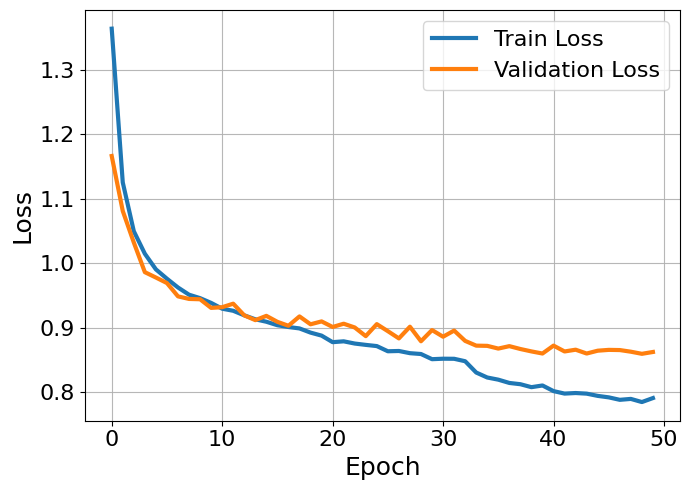


✅ Training Complete! Loss plot saved to: /home/rab/Downloads/forgery_10_octiber_effi/lossresnet34_.png


In [ ]:
# ==============================================================
# IMAGE FORGERY DETECTION TRAINING (RESNET-34 + AUGMENTATION & EARLY STOPPING)
# ==============================================================

import sys
import os
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
import torch.optim as optim
from sklearn.model_selection import train_test_split
import segmentation_models_pytorch as smp
import albumentations as A

# -------------------------------------------------------------
# 1. CONFIGURATION & PATHS
# -------------------------------------------------------------
BASE_DIR_TRAIN = Path("/home/rab/Downloads/forgery_data2_")  # Train & Val source
BASE_DIR_TEST  = Path("/home/rab/Downloads/forgery_data")    # Original Test source

TRAIN_IMAGE_DIR = BASE_DIR_TRAIN / "train_images"
TRAIN_MASK_DIR  = BASE_DIR_TRAIN / "train_masks"

TEST_IMAGE_DIR  = BASE_DIR_TEST / "test_images"
TEST_MASK_DIR   = BASE_DIR_TEST / "test_masks"

OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE = (256, 256)
BATCH_SIZE = 4
NUM_EPOCHS = 50
RANDOM_STATE = 42
NUM_WORKERS = 0
VAL_SPLIT = 0.20
LR = 3e-5
EARLY_STOPPING_PATIENCE = 8  # Stop if validation loss doesn't improve for 8 epochs

MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, "resnet34_model.pth")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print(f"Using Device: {DEVICE}")


# -------------------------------------------------------------
# 2. DATASET & AUGMENTATION UTILITIES
# -------------------------------------------------------------
def find_mask_file(mask_dir, img_name):
    stem = Path(img_name).stem
    for p in [f"{stem}.npy", f"{stem}_mask.npy"]:
        path = os.path.join(mask_dir, p)
        if os.path.exists(path):
            return path
    for root, _, files in os.walk(mask_dir):
        for f in files:
            if Path(f).stem == stem:
                return os.path.join(root, f)
    return None

def load_mask_safe(mask_path, target_shape):
    if mask_path is None or not os.path.exists(mask_path):
        return np.zeros(target_shape, dtype=np.uint8)
    mask = np.squeeze(np.load(mask_path, allow_pickle=True))
    if mask.ndim > 2:
        mask = mask[..., 0]
    mask = (mask > 0.5).astype(np.uint8)
    if mask.shape != target_shape:
        mask = cv2.resize((mask * 255).astype(np.uint8), (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)
    return mask

# Define augmentation pipelines using Albumentations with shape checks disabled
train_transform = A.Compose([
    A.Resize(IMG_SIZE[0], IMG_SIZE[1]),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=0.5, border_mode=cv2.BORDER_REFLECT_101),
    A.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, p=0.3),
], is_check_shapes=False)

val_transform = A.Compose([
    A.Resize(IMG_SIZE[0], IMG_SIZE[1]),
], is_check_shapes=False)

class ForgerySegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.transform = transform
        self.image_paths = []

        for folder in ["authentic", "forged"]:
            folder_path = Path(image_dir) / folder
            if folder_path.is_dir():
                for file in sorted(os.listdir(folder_path)):
                    if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                        self.image_paths.append(str(folder_path / file))

        self.mask_paths = [find_mask_file(mask_dir, Path(x).name) for x in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = cv2.imread(self.image_paths[index])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = load_mask_safe(self.mask_paths[index], IMG_SIZE)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        mask = torch.from_numpy(mask).unsqueeze(0).float()

        return image, mask

def get_image_class_from_path(img_path):
    return 1 if "forged" in Path(img_path).parts else 0


# -------------------------------------------------------------
# 3. DATA LOADERS & SPLIT
# -------------------------------------------------------------
full_train_dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, transform=train_transform)
full_val_dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, transform=val_transform)
test_dataset = ForgerySegmentationDataset(TEST_IMAGE_DIR, TEST_MASK_DIR, transform=val_transform)

targets = [get_image_class_from_path(p) for p in full_train_dataset.image_paths]

train_idx, val_idx = train_test_split(
    list(range(len(full_train_dataset))),
    test_size=VAL_SPLIT,
    random_state=RANDOM_STATE,
    stratify=targets
)

train_subset = Subset(full_train_dataset, train_idx)
val_subset = Subset(full_val_dataset, val_idx)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=False)
val_loader   = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=False)




# -------------------------------------------------------------
# 4. MODEL ARCHITECTURE (RESNET-34 U-NET)
# -------------------------------------------------------------
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)


# -------------------------------------------------------------
# 5. LOSS FUNCTIONS & OPTIMIZER
# -------------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-7):
        super().__init__()
        self.eps = eps
    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)
        intersection = (probs * targets).sum(dim=1)
        union = probs.sum(dim=1) + targets.sum(dim=1)
        loss = 1 - ((2 * intersection + self.eps) / (union + self.eps))
        return loss.mean()

bce = nn.BCEWithLogitsLoss()
dice = DiceLoss()

def combined_loss(logits, targets):
    return bce(logits, targets) + dice(logits, targets)

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-3)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.3, patience=3, min_lr=1e-6)
scaler = torch.amp.GradScaler('cuda' if DEVICE.type=='cuda' else None)


# -------------------------------------------------------------
# 6. TRAINING LOOP WITH EARLY STOPPING
# -------------------------------------------------------------
best_val = 1e9
patience_counter = 0
train_losses_all, val_losses_all = [], []

print("\nStarting Training with ResNet-34 U-Net & Augmentation...")
for epoch in range(1, NUM_EPOCHS + 1):
    # TRAIN
    model.train()
    train_losses = []
    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch} TRAIN", leave=False):
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()

        with torch.autocast(device_type=DEVICE.type, enabled=DEVICE.type=='cuda'):
            logits = model(images)
            if logits.shape[2:] != masks.shape[2:]:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')
            loss = combined_loss(logits, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        train_losses.append(loss.item())

    # VALIDATION
    model.eval()
    val_losses = []
    with torch.no_grad():
        for images, masks in tqdm(val_loader, desc=f"Epoch {epoch} VAL", leave=False):
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            logits = model(images)
            if logits.shape[2:] != masks.shape[2:]:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')
            loss = combined_loss(logits, masks)
            val_losses.append(loss.item())

    avg_train_loss = np.mean(train_losses)
    avg_val_loss = np.mean(val_losses)

    print(f"Epoch {epoch}: Train Loss {avg_train_loss:.4f} | Val Loss {avg_val_loss:.4f}")

    train_losses_all.append(avg_train_loss)
    val_losses_all.append(avg_val_loss)

    scheduler.step(avg_val_loss)

    # Checkpoint & Early Stopping Check
    if avg_val_loss < best_val:
        best_val = avg_val_loss
        torch.save(model.state_dict(), MODEL_SAVE_PATH)
        patience_counter = 0
        print(f"✅ Saved best model (Val Loss: {best_val:.4f})")
    else:
        patience_counter += 1
        print(f"⚠️ Validation loss did not improve. Patience: {patience_counter}/{EARLY_STOPPING_PATIENCE}")
        if patience_counter >= EARLY_STOPPING_PATIENCE:
            print(f"\n🛑 Early stopping triggered at epoch {epoch} to prevent overfitting!")
            break

# -------------------------------------------------------------
# 7. LOSS CURVE PLOTTING
# -------------------------------------------------------------
plt.figure(figsize=(7, 5))
plt.plot(train_losses_all, label="Train Loss", linewidth=3)
plt.plot(val_losses_all, label="Validation Loss", linewidth=3)
plt.xlabel("Epoch", fontsize=18)
plt.ylabel("Loss", fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.grid(alpha=0.9)
plt.tight_layout()

loss_plot_path = os.path.join(OUTPUT_DIR, "lossresnet34_.png")
plt.savefig(loss_plot_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✅ Training Complete! Loss plot saved to: {loss_plot_path}")

⚠️ Running evaluation on: cpu
Loading dataset and recreating exact sequential split...
Loading trained ResNet-34 U-Net architecture and weights...


/tmp/ipykernel_12604/3749795633.py:142: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


✅ Successfully loaded ResNet-34 model weights from: /home/rab/Downloads/forgery_10_octiber_effi/resnet34_model.pth

🔍 EVALUATING ON VALIDATION SET


Computing Class-wise Metrics: 100%|██████████| 257/257 [00:37<00:00,  6.79it/s]



Authentic
  Dice           : 0.9799
  IoU            : 0.9606
  MCC            : 0.5027
  Hamming Loss   : 0.0385

Forged
  Dice           : 0.5204
  IoU            : 0.3518
  MCC            : 0.5027
  Hamming Loss   : 0.0385

Macro Average
  Dice           : 0.7502
  IoU            : 0.6562
  MCC            : 0.5027
  Hamming Loss   : 0.0385

🔍 EVALUATING ON TEST SET (Localization, Centroids, Plots)


Test Set Inference: 100%|████████████████████| 257/257 [00:35<00:00,  7.29it/s]


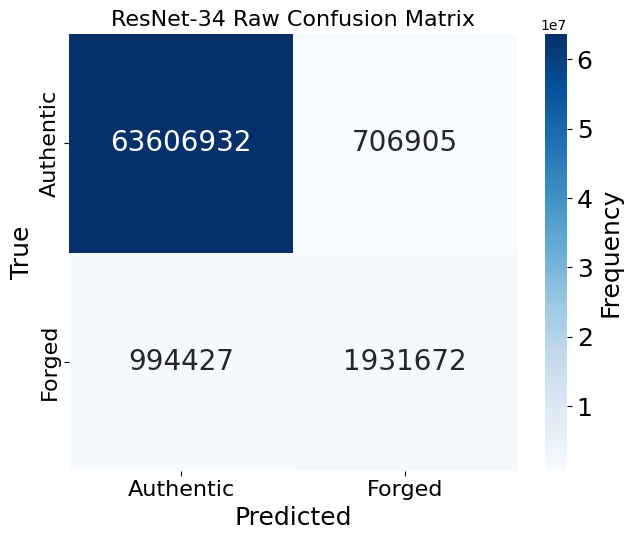

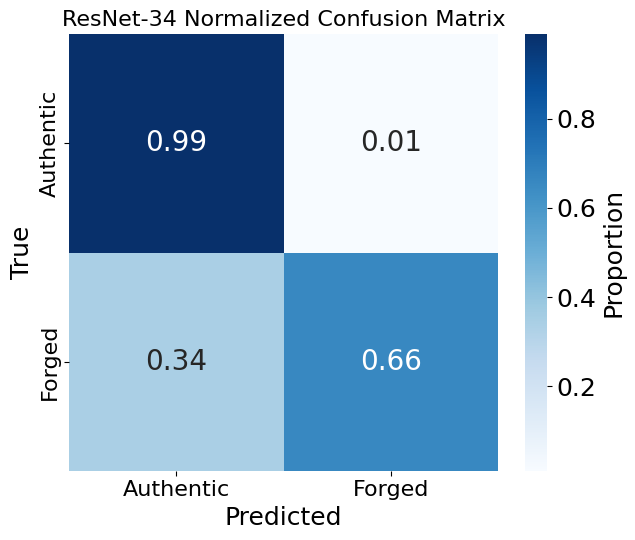

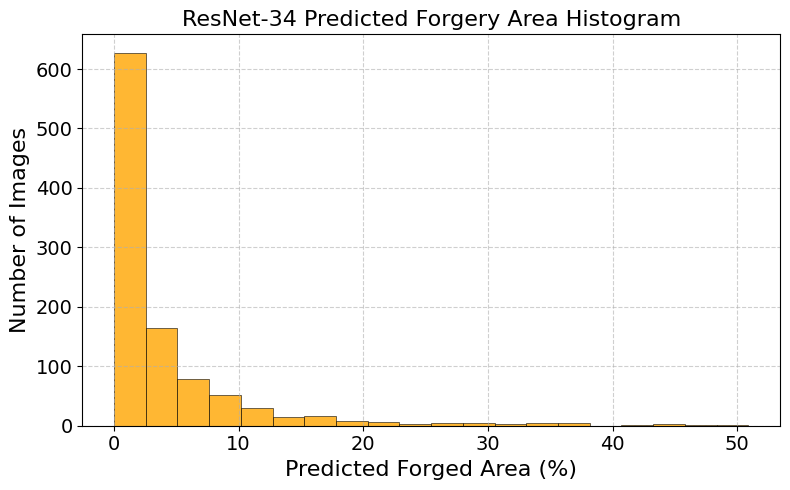


✅ EVALUATION COMPLETE — RESNET-34 TEST SET RESULTS
Mean predicted forgery area: 3.92%
Localization IoU           : 0.3741
Centroid Error (px)        : 43.67

📁 Unique plots saved to   : /home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34


In [ ]:
# ============================================================
# RESNET-34 FORGERY DETECTION EVALUATION (CPU-SAFE & EXACT SPLIT)
# - Recreates exact sequential split (20% Val, 25% Test from Train)
# - Evaluates validation set and test set securely on CPU
# - Generates confusion matrices, histograms, and localization metrics
# ============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp
import cv2

IMG_SIZE = (256, 256)
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 0
RANDOM_STATE = 42

BASE_DIR_TRAIN = Path("/home/rab/Downloads/forgery_data2_")
TRAIN_IMAGE_DIR = BASE_DIR_TRAIN / "train_images"
TRAIN_MASK_DIR  = BASE_DIR_TRAIN / "train_masks"

# Dedicated separate directory for ResNet-34 evaluation outputs
OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
MODEL_SAVE_PATH = os.path.join(MODEL_DIR, "resnet34_model.pth")

# 🔴 Force CPU for evaluation to bypass GPU OOM issues
DEVICE = torch.device("cpu")
print(f"⚠️ Running evaluation on: {DEVICE}")

# -----------------------------
# DATASET & EXACT SEQUENTIAL SPLIT
# -----------------------------
def find_mask_file(mask_dir, img_name):
    stem = Path(img_name).stem
    for p in [f"{stem}.npy", f"{stem}_mask.npy"]:
        path = os.path.join(mask_dir, p)
        if os.path.exists(path):
            return path
    for root, _, files in os.walk(mask_dir):
        for f in files:
            if Path(f).stem == stem:
                return os.path.join(root, f)
    return None

def load_mask_safe(mask_path, target_shape):
    if mask_path is None or not os.path.exists(mask_path):
        return np.zeros(target_shape, dtype=np.uint8)
    mask = np.squeeze(np.load(mask_path, allow_pickle=True))
    if mask.ndim > 2:
        mask = mask[..., 0]
    mask = (mask > 0.5).astype(np.uint8)
    if mask.shape != target_shape:
        mask = cv2.resize((mask * 255).astype(np.uint8), (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)
    return mask

class ForgerySegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, img_size=IMG_SIZE):
        self.img_size = img_size
        self.image_paths = []
        for folder in ["authentic", "forged"]:
            folder_path = Path(image_dir) / folder
            if folder_path.is_dir():
                for file in sorted(os.listdir(folder_path)):
                    if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                        self.image_paths.append(str(folder_path / file))
        self.mask_paths = [find_mask_file(mask_dir, Path(x).name) for x in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = cv2.imread(self.image_paths[index])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.img_size[1], self.img_size[0]))
        mask = load_mask_safe(self.mask_paths[index], (self.img_size[0], self.img_size[1]))
        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        mask = torch.from_numpy(mask).unsqueeze(0).float()
        return image, mask

def get_image_class_from_path(img_path):
    return 1 if "forged" in Path(img_path).parts else 0

print("Loading dataset and recreating exact sequential split...")
dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
targets = [get_image_class_from_path(p) for p in dataset.image_paths]

# Step 1: 20% validation set, 80% training pool
train_pool_idx, val_idx = train_test_split(
    list(range(len(dataset))),
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=targets
)

# Step 2: 25% test set from the training pool
train_pool_targets = [targets[i] for i in train_pool_idx]
train_idx, test_idx = train_test_split(
    train_pool_idx,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=train_pool_targets
)

val_subset = Subset(dataset, val_idx)
test_subset = Subset(dataset, test_idx)

val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# -----------------------------
# RE-INITIALIZE & LOAD RESNET-34 MODEL
# -----------------------------
print("Loading trained ResNet-34 U-Net architecture and weights...")
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded ResNet-34 model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}. Please verify your model path.")

# -----------------------------
# METRIC HELPERS & REUSABLE FUNCTION
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

def compute_classwise_metrics(model, loader, device, threshold=0.5):
    model.eval()
    stats = {
        0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},
        1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},
    }
    y_true_all, y_pred_all = [], []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Computing Class-wise Metrics"):
            images = images.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.float32)

            logits = model(images)
            if logits.shape != masks.shape:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')

            probs = torch.sigmoid(logits)
            preds = (probs > threshold).long()
            gt = masks.long()

            gt_f = gt.view(-1).cpu().numpy()
            pred_f = preds.view(-1).cpu().numpy()

            y_true_all.append(gt_f)
            y_pred_all.append(pred_f)

            for cls in [0, 1]:
                tp = np.sum((pred_f == cls) & (gt_f == cls))
                fp = np.sum((pred_f == cls) & (gt_f != cls))
                fn = np.sum((pred_f != cls) & (gt_f == cls))
                tn = np.sum((pred_f != cls) & (gt_f != cls))

                stats[cls]["tp"] += tp
                stats[cls]["fp"] += fp
                stats[cls]["fn"] += fn
                stats[cls]["tn"] += tn

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    results = {}
    for cls, name in zip([0, 1], ["Authentic", "Forged"]):
        tp = stats[cls]["tp"]
        fp = stats[cls]["fp"]
        fn = stats[cls]["fn"]
        tn = stats[cls]["tn"]

        dice = dice_score(tp, fp, fn)
        iou = iou_score(tp, fp, fn)
        mcc = matthews_corrcoef((y_true_all == cls).astype(int), (y_pred_all == cls).astype(int))
        h_loss = hamming_loss((y_true_all == cls).astype(int), (y_pred_all == cls).astype(int))

        results[name] = {
            "Dice": dice,
            "IoU": iou,
            "MCC": mcc,
            "Hamming Loss": h_loss
        }

    results["Macro Average"] = {
        m: np.mean([results["Authentic"][m], results["Forged"][m]])
        for m in ["Dice", "IoU", "MCC", "Hamming Loss"]
    }
    return results, y_true_all, y_pred_all

# -----------------------------
# 1. VALIDATION SET EVALUATION
# -----------------------------
print("\n" + "="*80)
print("🔍 EVALUATING ON VALIDATION SET")
print("="*80)
val_metrics, _, _ = compute_classwise_metrics(model, val_loader, DEVICE, threshold=THRESHOLD)
for cls, vals in val_metrics.items():
    print(f"\n{cls}")
    for k, v in vals.items():
        print(f"  {k:15s}: {v:.4f}")

# -----------------------------
# 2. TEST SET DEEP EVALUATION & PLOTS
# -----------------------------
print("\n" + "="*80)
print("🔍 EVALUATING ON TEST SET (Localization, Centroids, Plots)")
print("="*80)

model.eval()
y_true_flat_all, y_pred_flat_all = [], []
stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc, centroid_errors, gt_area_pcts, pred_area_pcts, abs_area_errs = [], [], [], [], []
tcrs, fars = [], []
gt_pixel_counts, pred_pixel_counts, pred_area_fractions = [], [], []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test Set Inference"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            stats[cls]["tp"] += np.sum((pred_flat == cls) & (gt_flat == cls))
            stats[cls]["fp"] += np.sum((pred_flat == cls) & (gt_flat != cls))
            stats[cls]["fn"] += np.sum((pred_flat != cls) & (gt_flat == cls))
            stats[cls]["tn"] += np.sum((pred_flat != cls) & (gt_flat != cls))

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px, pred_px = int(gt.sum()), int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                tcrs.append(np.logical_and(pred == 1, gt == 1).sum() / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                fars.append(np.logical_and(pred == 1, gt == 0).sum() / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# Safe Relative Area Diff
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)
valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# Confusion Matrices & Unique Figure Plots
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm, annot=annot, fmt=fmt, cmap="Blues", cbar=True,
        xticklabels=["Authentic", "Forged"], yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)
    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

# Save with distinct filenames
save_cm_plot(cm_raw, "ResNet-34 Raw Confusion Matrix", "resnet34_cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "ResNet-34 Normalized Confusion Matrix", "resnet34_cm_norm.png", normalize=True)

# Histogram Plot with distinct filename
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.title("ResNet-34 Predicted Forgery Area Histogram", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "resnet34_predicted_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Aggregate Metrics
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# Print Test Results Summary
print("\n" + "="*80)
print("✅ EVALUATION COMPLETE — RESNET-34 TEST SET RESULTS")
print("="*80)
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Localization IoU           : {loc_metrics['Localization IoU']:.4f}")
print(f"Centroid Error (px)        : {loc_metrics['Centroid Error (px)']:.2f}")
print(f"\n📁 Unique plots saved to   : {OUTPUT_DIR}")
print("="*80)

/tmp/ipykernel_12604/949951822.py:59: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


Loading trained ResNet-34 model architecture and weights...
✅ Successfully loaded ResNet-34 model weights from: /home/rab/Downloads/forgery_10_octiber_effi/resnet34_model.pth


Test Inference: 100%|████████████████████████| 257/257 [00:21<00:00, 12.02it/s]


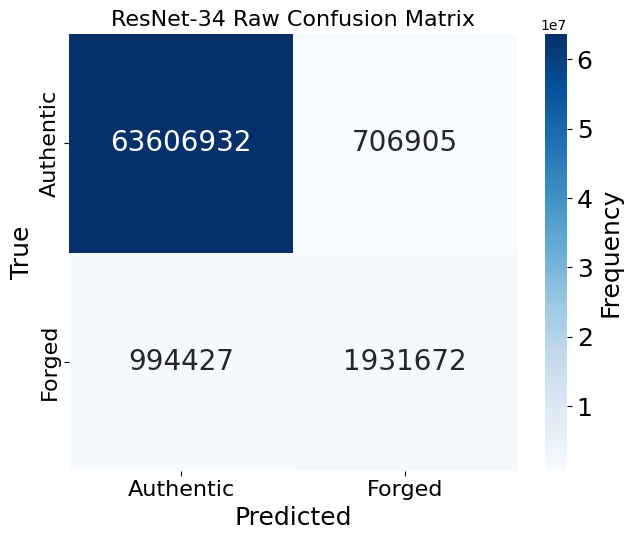

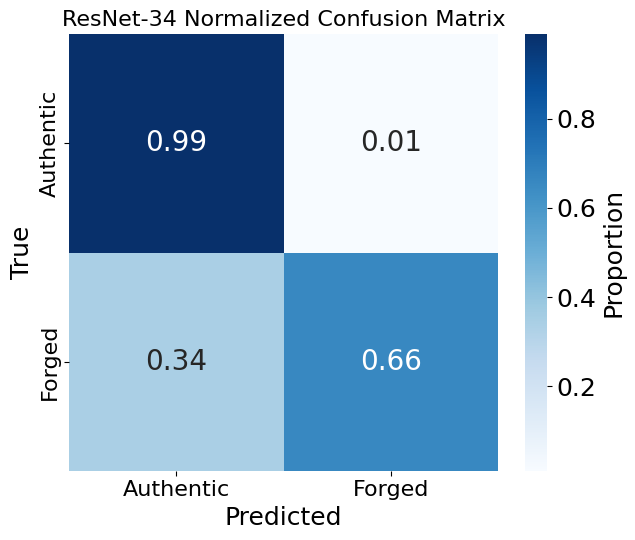

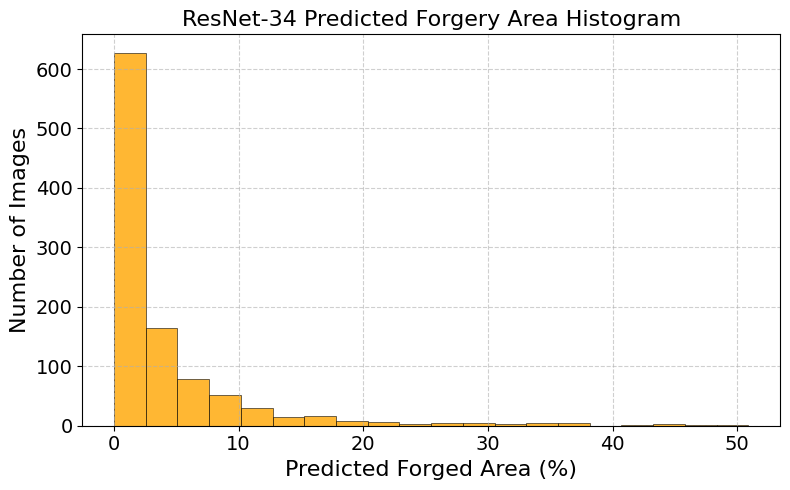


✅ EVALUATION COMPLETE — RESNET-34 TEST SET RESULTS
Mean predicted forgery area: 3.92%
Localization IoU           : 0.3741
Centroid Error (px)        : 43.67

📁 Unique plots saved to   : /home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34


In [ ]:
# ==============================================================
# CELL 2: MODEL EVALUATION ON THE EXACT TEST SUBSET (RESNET-34)
# ==============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp

# -----------------------------
# Configuration & Directory Setup
# -----------------------------
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2

# Separate output directory for ResNet-34 evaluation results
OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
MODEL_SAVE_PATH = os.path.join(MODEL_DIR, "resnet34_model.pth")
DEVICE = torch.device("cpu")  # Using CPU to bypass any shared VRAM limits

# Build DataLoader using the test_idx from Cell 1
test_subset = Subset(dataset, test_idx)
test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# -----------------------------
# Load Model Weights
# -----------------------------
print("Loading trained ResNet-34 model architecture and weights...")
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded ResNet-34 model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}.")

# -----------------------------
# Metric Helpers
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

# -----------------------------
# Inference + Metrics Collection
# -----------------------------
model.eval()

y_true_flat_all = []
y_pred_flat_all = []
stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc, centroid_errors, gt_area_pcts, pred_area_pcts, abs_area_errs = [], [], [], [], []
tcrs, fars = [], []
gt_pixel_counts, pred_pixel_counts, pred_area_fractions = [], [], []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test Inference"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            stats[cls]["tp"] += np.sum((pred_flat == cls) & (gt_flat == cls))
            stats[cls]["fp"] += np.sum((pred_flat == cls) & (gt_flat != cls))
            stats[cls]["fn"] += np.sum((pred_flat != cls) & (gt_flat == cls))
            stats[cls]["tn"] += np.sum((pred_flat != cls) & (gt_flat != cls))

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px, pred_px = int(gt.sum()), int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                tcrs.append(np.logical_and(pred == 1, gt == 1).sum() / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                fars.append(np.logical_and(pred == 1, gt == 0).sum() / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# Safe Relative Area Diff
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)
valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# Confusion Matrices & Plots
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm, annot=annot, fmt=fmt, cmap="Blues", cbar=True,
        xticklabels=["Authentic", "Forged"], yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)
    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

save_cm_plot(cm_raw, "ResNet-34 Raw Confusion Matrix", "resnet34_cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "ResNet-34 Normalized Confusion Matrix", "resnet34_cm_norm.png", normalize=True)

# Histogram Plot
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.title("ResNet-34 Predicted Forgery Area Histogram", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "resnet34_predicted_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Aggregate Metrics
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# Results Summary
print("\n" + "="*80)
print("✅ EVALUATION COMPLETE — RESNET-34 TEST SET RESULTS")
print("="*80)
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Localization IoU           : {loc_metrics['Localization IoU']:.4f}")
print(f"Centroid Error (px)        : {loc_metrics['Centroid Error (px)']:.2f}")
print(f"\n📁 Unique plots saved to   : {OUTPUT_DIR}")
print("="*80)

/tmp/ipykernel_12604/893891479.py:60: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


⚠️ Running evaluation on: cpu
Loading trained ResNet-34 model architecture and weights...
✅ Successfully loaded ResNet-34 model weights from: /home/rab/Downloads/forgery_10_octiber_effi/resnet34_model.pth
PREVIOUSLY SPLIT TEST DATASET IMAGE STATS
Total: 1026, Authentic: 475, Forged: 551


Inference & Metrics: 100%|███████████████████| 257/257 [00:22<00:00, 11.37it/s]


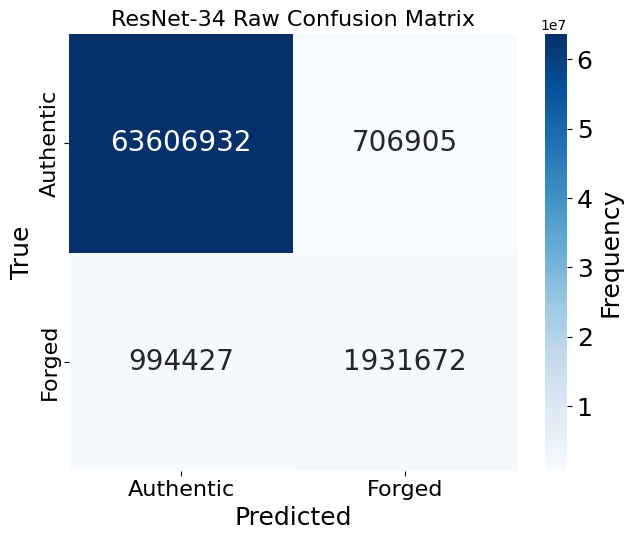

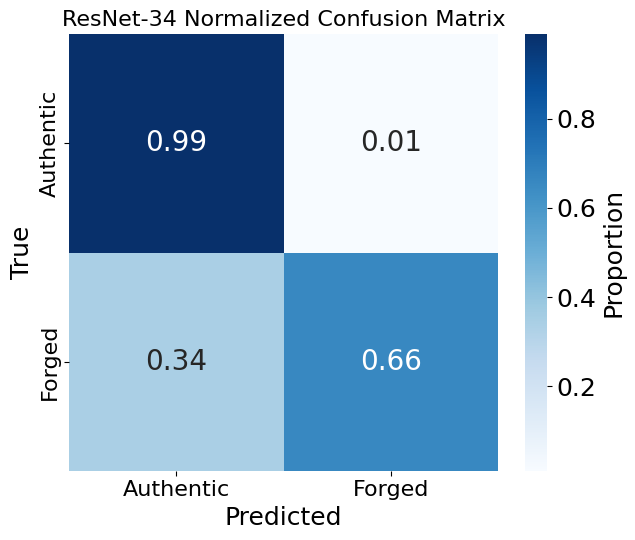

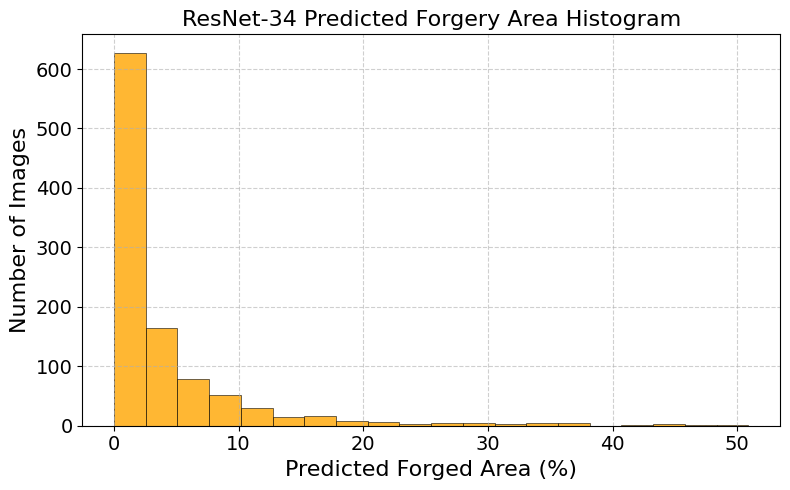


✅ EVALUATION COMPLETE — RESNET-34 TEST RESULTS
📊 PIXEL-LEVEL CLASSIFICATION METRICS
---------------------------------------------
Class        | Precision |    Recall |        F1
Authentic    |    0.9846 |    0.9890 |    0.9868
Forged       |    0.7321 |    0.6602 |    0.6943
Macro Avg    |    0.8583 |    0.8246 |    0.8405

🔍 CLASS-WISE ROBUST METRICS
---------------------------------------------

Authentic
  Dice           : 0.9868
  IoU            : 0.9739
  MCC            : 0.6821
  Hamming Loss   : 0.0253

Forged
  Dice           : 0.6943
  IoU            : 0.5317
  MCC            : 0.6821
  Hamming Loss   : 0.0253

Macro Average
  Dice           : 0.8405
  IoU            : 0.7528
  MCC            : 0.6821
  Hamming Loss   : 0.0253

📍 FORGERY LOCALIZATION METRICS
---------------------------------------------
Localization IoU              : 0.3741
Centroid Error (px)           : 43.67
Avg GT Forged Area (%)        : 4.3517
Avg Pred Forged Area (%)      : 3.9241
Abs Area Error (%) 

In [ ]:
# ============================================================
# COMPLETE FORGERY DETECTION EVALUATION (RESNET-34 TEST SPLIT)
# - Uses previously defined dataset, train_idx, and sequential test_idx
# - Evaluates on CPU to prevent OOM
# - Generates confusion matrices, metrics, and histograms
# ============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from collections import Counter
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp

# -----------------------------
# CONFIGURATION
# -----------------------------
TEST_FRACTION = 0.25
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2
RANDOM_STATE = 42

# Dedicated separate output directory for ResNet-34 evaluation
OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
MODEL_SAVE_PATH = os.path.join(MODEL_DIR, "resnet34_model.pth")

# 🔴 Force CPU for evaluation to bypass OOM errors from other processes
DEVICE = torch.device("cpu")
print(f"⚠️ Running evaluation on: {DEVICE}")

# -----------------------------
# RE-INITIALIZE & LOAD RESNET-34 MODEL
# -----------------------------
print("Loading trained ResNet-34 model architecture and weights...")
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded ResNet-34 model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}. Please run training first.")

# -----------------------------
# Helper: infer image class
# -----------------------------
def get_image_class(img_path):
    parts = Path(img_path).parts
    if "authentic" in parts:
        return 0
    elif "forged" in parts:
        return 1
    else:
        raise ValueError(f"Unknown class for {img_path}")

# Recreate the exact 25% test split from the train pool if not already in memory
if 'test_idx' not in globals():
    targets = [get_image_class(dataset.image_paths[i]) for i in range(len(dataset))]
    train_pool_idx, _ = train_test_split(
        list(range(len(dataset))),
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=targets
    )
    train_pool_targets = [targets[i] for i in train_pool_idx]
    _, test_idx = train_test_split(
        train_pool_idx,
        test_size=TEST_FRACTION,
        random_state=RANDOM_STATE,
        stratify=train_pool_targets
    )

test_subset = Subset(dataset, test_idx)
test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=False
)

# -----------------------------
# IMAGE-LEVEL STATS
# -----------------------------
subset_labels = [get_image_class(dataset.image_paths[i]) for i in test_idx]
print("=" * 80)
print("PREVIOUSLY SPLIT TEST DATASET IMAGE STATS")
print(f"Total: {len(subset_labels)}, Authentic: {Counter(subset_labels)[0]}, Forged: {Counter(subset_labels)[1]}")
print("=" * 80)

# -----------------------------
# METRIC HELPERS
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

# -----------------------------
# INFERENCE + METRICS COLLECTION
# -----------------------------
model.eval()

y_true_flat_all = []
y_pred_flat_all = []

stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc = []
centroid_errors = []
gt_area_pcts = []
pred_area_pcts = []
abs_area_errs = []
tcrs = []
fars = []

gt_pixel_counts = []
pred_pixel_counts = []
pred_area_fractions = []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Inference & Metrics"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            tp = np.sum((pred_flat == cls) & (gt_flat == cls))
            fp = np.sum((pred_flat == cls) & (gt_flat != cls))
            fn = np.sum((pred_flat != cls) & (gt_flat == cls))
            tn = np.sum((pred_flat != cls) & (gt_flat != cls))
            stats[cls]["tp"] += tp
            stats[cls]["fp"] += fp
            stats[cls]["fn"] += fn
            stats[cls]["tn"] += tn

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px = int(gt.sum())
            pred_px = int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                TP_reg = np.logical_and(pred == 1, gt == 1).sum()
                tcrs.append(TP_reg / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                FP_reg = np.logical_and(pred == 1, gt == 0).sum()
                fars.append(FP_reg / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# -----------------------------
# SAFE RELATIVE AREA DIFF
# -----------------------------
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)

valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) \
                     / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# -----------------------------
# CONFUSION MATRIX PLOTS
# -----------------------------
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm,
        annot=annot,
        fmt=fmt,
        cmap="Blues",
        cbar=True,
        xticklabels=["Authentic", "Forged"],
        yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )

    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)

    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

save_cm_plot(cm_raw, "ResNet-34 Raw Confusion Matrix", "resnet34_cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "ResNet-34 Normalized Confusion Matrix", "resnet34_cm_norm.png", normalize=True)

# -----------------------------
# HISTOGRAM PLOT
# -----------------------------
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.title("ResNet-34 Predicted Forgery Area Histogram", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "resnet34_predicted_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# -----------------------------
# AGGREGATE METRICS
# -----------------------------
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
prec_macro = precision_score(y_true_flat_all, y_pred_flat_all, average="macro")
rec_macro = recall_score(y_true_flat_all, y_pred_flat_all, average="macro")
f1_macro = f1_score(y_true_flat_all, y_pred_flat_all, average="macro")

class_results = {}
for cls, name in zip([0, 1], ["Authentic", "Forged"]):
    tp, fp, fn, tn = stats[cls]["tp"], stats[cls]["fp"], stats[cls]["fn"], stats[cls]["tn"]
    dice_val = dice_score(tp, fp, fn)
    iou_val = iou_score(tp, fp, fn)
    y_bin_true = (y_true_flat_all == cls).astype(int)
    y_bin_pred = (y_pred_flat_all == cls).astype(int)
    mcc_val = matthews_corrcoef(y_bin_true, y_bin_pred)
    hamming_val = hamming_loss(y_bin_true, y_bin_pred)
    class_results[name] = {
        "Dice": dice_val, "IoU": iou_val, "MCC": mcc_val, "Hamming Loss": hamming_val
    }

macro_avg = {
    m: np.nanmean([class_results["Authentic"][m], class_results["Forged"][m]])
    for m in ["Dice", "IoU", "MCC", "Hamming Loss"]
}
class_results["Macro Average"] = macro_avg

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# -----------------------------
# PRINT RESULTS
# -----------------------------
print("\n" + "="*80)
print("✅ EVALUATION COMPLETE — RESNET-34 TEST RESULTS")
print("="*80)

print("📊 PIXEL-LEVEL CLASSIFICATION METRICS")
print("-" * 45)
print(f"{'Class':12s} | {'Precision':>9s} | {'Recall':>9s} | {'F1':>9s}")
for i, name in enumerate(["Authentic", "Forged"]):
    print(f"{name:12s} | {prec[i]:9.4f} | {rec[i]:9.4f} | {f1[i]:9.4f}")
print(f"{'Macro Avg':12s} | {prec_macro:9.4f} | {rec_macro:9.4f} | {f1_macro:9.4f}")

print("\n🔍 CLASS-WISE ROBUST METRICS")
print("-" * 45)
for cls, vals in class_results.items():
    print(f"\n{cls}")
    for k, v in vals.items():
        print(f"  {k:15s}: {v:.4f}")

print("\n📍 FORGERY LOCALIZATION METRICS")
print("-" * 45)
for k, v in loc_metrics.items():
    if k == "Centroid Error (px)":
        print(f"{k:30s}: {v:.2f}" if not np.isnan(v) else f"{k:30s}: NaN")
    else:
        print(f"{k:30s}: {v:.4f}" if not np.isnan(v) else f"{k:30s}: NaN")

print("\n📈 PREDICTED FORGERY AREA (ALL IMAGES)")
print("-" * 45)
n_images = len(pred_area_percentages)
print(f"Total images evaluated     : {n_images}")
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Std deviation              : {pred_area_percentages.std():.2f}%")
print(f"Min / Max                  : {pred_area_percentages.min():.2f}% / {pred_area_percentages.max():.2f}%")
print(f"Median                     : {np.median(pred_area_percentages):.2f}%")

print("\n📁 Outputs saved to:")
print(f"    → {os.path.join(OUTPUT_DIR, 'resnet34_cm_raw.png')}")
print(f"    → {os.path.join(OUTPUT_DIR, 'resnet34_cm_norm.png')}")
print(f"    → {os.path.join(OUTPUT_DIR, 'resnet34_predicted_area_hist.png')}")
print("="*80)

/tmp/ipykernel_12604/2410101117.py:59: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


Loading trained ResNet-34 model architecture and weights...
✅ Successfully loaded ResNet-34 model weights from: /home/rab/Downloads/forgery_10_octiber_effi/resnet34_model.pth


Test Inference: 100%|████████████████████████| 257/257 [00:21<00:00, 12.23it/s]


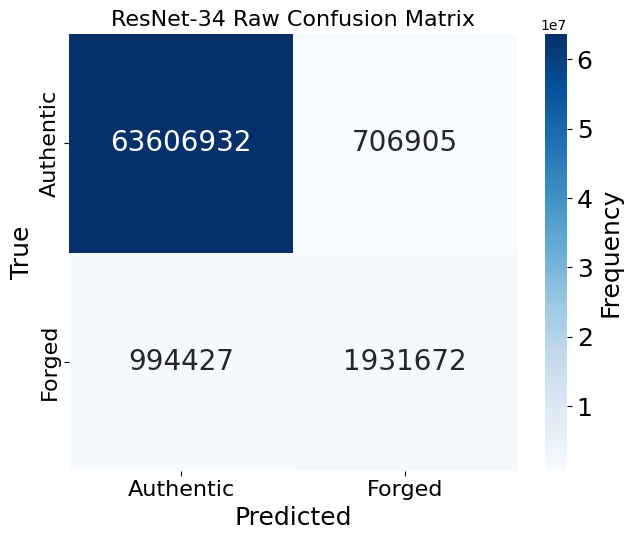

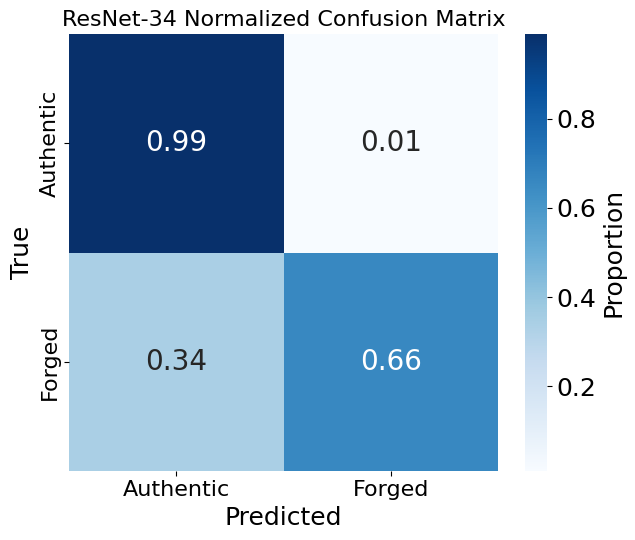

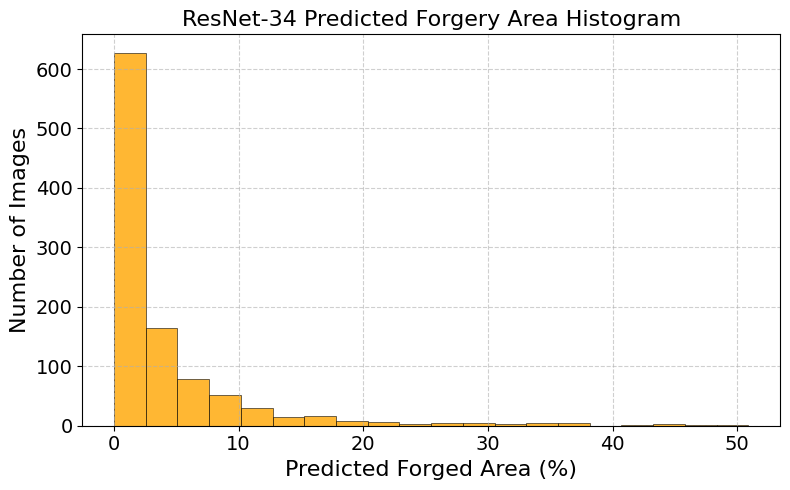


✅ EVALUATION COMPLETE — RESNET-34 TEST SET RESULTS
Mean predicted forgery area: 3.92%
Localization IoU           : 0.3741
Centroid Error (px)        : 43.67

📁 Plots saved to          : /home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34


In [ ]:
# ==============================================================
# CELL 2: MODEL EVALUATION ON THE EXACT TEST SUBSET (RESNET-34)
# ==============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp

# -----------------------------
# Configuration
# -----------------------------
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2

# Dedicated separate output directory for ResNet-34 evaluation results
OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
MODEL_SAVE_PATH = os.path.join(MODEL_DIR, "resnet34_model.pth")
DEVICE = torch.device("cpu")  # Using CPU to bypass any shared VRAM limits

# Build DataLoader using the test_idx from Cell 1
test_subset = Subset(dataset, test_idx)
test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# -----------------------------
# Load Model Weights
# -----------------------------
print("Loading trained ResNet-34 model architecture and weights...")
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded ResNet-34 model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}.")

# -----------------------------
# Metric Helpers
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

# -----------------------------
# Inference + Metrics Collection
# -----------------------------
model.eval()

y_true_flat_all = []
y_pred_flat_all = []
stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc, centroid_errors, gt_area_pcts, pred_area_pcts, abs_area_errs = [], [], [], [], []
tcrs, fars = [], []
gt_pixel_counts, pred_pixel_counts, pred_area_fractions = [], [], []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test Inference"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            stats[cls]["tp"] += np.sum((pred_flat == cls) & (gt_flat == cls))
            stats[cls]["fp"] += np.sum((pred_flat == cls) & (gt_flat != cls))
            stats[cls]["fn"] += np.sum((pred_flat != cls) & (gt_flat == cls))
            stats[cls]["tn"] += np.sum((pred_flat != cls) & (gt_flat != cls))

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px, pred_px = int(gt.sum()), int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                tcrs.append(np.logical_and(pred == 1, gt == 1).sum() / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                fars.append(np.logical_and(pred == 1, gt == 0).sum() / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# Safe Relative Area Diff
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)
valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# Confusion Matrices & Plots
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm, annot=annot, fmt=fmt, cmap="Blues", cbar=True,
        xticklabels=["Authentic", "Forged"], yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)
    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

save_cm_plot(cm_raw, "ResNet-34 Raw Confusion Matrix", "resnet34_cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "ResNet-34 Normalized Confusion Matrix", "resnet34_cm_norm.png", normalize=True)

# Histogram Plot
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.title("ResNet-34 Predicted Forgery Area Histogram", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "resnet34_predicted_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Aggregate Metrics
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# Results Summary
print("\n" + "="*80)
print("✅ EVALUATION COMPLETE — RESNET-34 TEST SET RESULTS")
print("="*80)
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Localization IoU           : {loc_metrics['Localization IoU']:.4f}")
print(f"Centroid Error (px)        : {loc_metrics['Centroid Error (px)']:.2f}")
print(f"\n📁 Plots saved to          : {OUTPUT_DIR}")
print("="*80)

/tmp/ipykernel_12604/811033342.py:143: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


⚠️ Running evaluation on: cpu
Loading dataset and recreating exact sequential split...
Loading trained ResNet-34 model architecture and weights...
✅ Successfully loaded ResNet-34 model weights from: /home/rab/Downloads/forgery_10_octiber_effi/resnet34_model.pth

🔍 EVALUATING ON VALIDATION SET


Computing Class-wise Metrics: 100%|██████████| 257/257 [00:22<00:00, 11.57it/s]



Authentic
  Dice           : 0.9799
  IoU            : 0.9606
  MCC            : 0.5027
  Hamming Loss   : 0.0385

Forged
  Dice           : 0.5204
  IoU            : 0.3518
  MCC            : 0.5027
  Hamming Loss   : 0.0385

Macro Average
  Dice           : 0.7502
  IoU            : 0.6562
  MCC            : 0.5027
  Hamming Loss   : 0.0385

🔍 EVALUATING ON TEST SET (Localization, Centroids, Plots)


Test Set Inference: 100%|████████████████████| 257/257 [00:21<00:00, 11.90it/s]


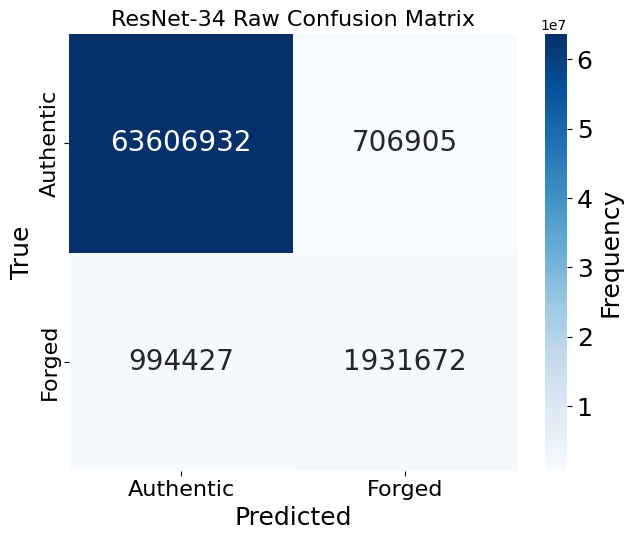

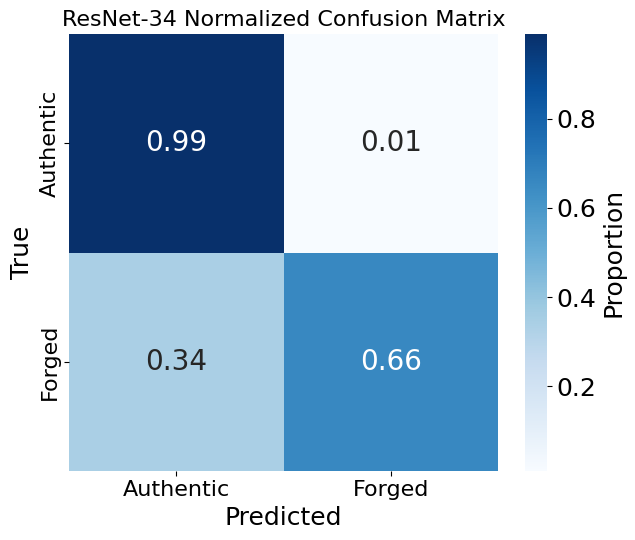

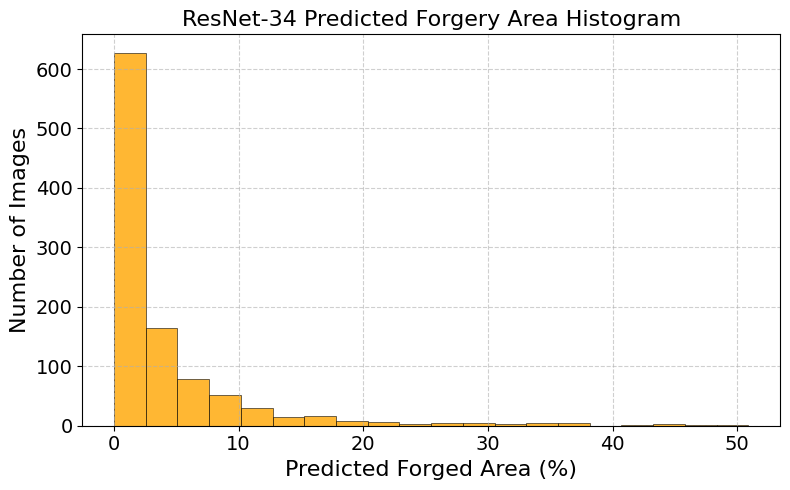


✅ TEST SET EVALUATION COMPLETE — RESNET-34 RESULTS
Mean predicted forgery area: 3.92%
Localization IoU           : 0.3741
Centroid Error (px)        : 43.67

📁 Plots saved to          : /home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34


In [ ]:
# ============================================================
# COMPLETE FORGERY DETECTION EVALUATION (CPU-SAFE & EXACT SPLIT) - RESNET-34
# - Recreates exact sequential split (20% Val, 25% Test from Train)
# - Evaluates validation set and test set securely on CPU
# - Generates confusion matrices, histograms, and localization metrics
# ============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from collections import Counter
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp
import cv2

IMG_SIZE = (256, 256)
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2
RANDOM_STATE = 42

BASE_DIR_TRAIN = Path("/home/rab/Downloads/forgery_data2_")
TRAIN_IMAGE_DIR = BASE_DIR_TRAIN / "train_images"
TRAIN_MASK_DIR  = BASE_DIR_TRAIN / "train_masks"

# Dedicated separate output directory for ResNet-34 evaluation results
OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
MODEL_SAVE_PATH = os.path.join(MODEL_DIR, "resnet34_model.pth")

# 🔴 Force CPU for evaluation to bypass GPU OOM issues
DEVICE = torch.device("cpu")
print(f"⚠️ Running evaluation on: {DEVICE}")

# -----------------------------
# DATASET & EXACT SEQUENTIAL SPLIT
# -----------------------------
def find_mask_file(mask_dir, img_name):
    stem = Path(img_name).stem
    for p in [f"{stem}.npy", f"{stem}_mask.npy"]:
        path = os.path.join(mask_dir, p)
        if os.path.exists(path):
            return path
    for root, _, files in os.walk(mask_dir):
        for f in files:
            if Path(f).stem == stem:
                return os.path.join(root, f)
    return None

def load_mask_safe(mask_path, target_shape):
    if mask_path is None or not os.path.exists(mask_path):
        return np.zeros(target_shape, dtype=np.uint8)
    mask = np.squeeze(np.load(mask_path, allow_pickle=True))
    if mask.ndim > 2:
        mask = mask[..., 0]
    mask = (mask > 0.5).astype(np.uint8)
    if mask.shape != target_shape:
        mask = cv2.resize((mask * 255).astype(np.uint8), (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)
    return mask

class ForgerySegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, img_size=IMG_SIZE):
        self.img_size = img_size
        self.image_paths = []
        for folder in ["authentic", "forged"]:
            folder_path = Path(image_dir) / folder
            if folder_path.is_dir():
                for file in sorted(os.listdir(folder_path)):
                    if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                        self.image_paths.append(str(folder_path / file))
        self.mask_paths = [find_mask_file(mask_dir, Path(x).name) for x in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = cv2.imread(self.image_paths[index])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.img_size[1], self.img_size[0]))
        mask = load_mask_safe(self.mask_paths[index], (self.img_size[0], self.img_size[1]))
        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        mask = torch.from_numpy(mask).unsqueeze(0).float()
        return image, mask

def get_image_class_from_path(img_path):
    return 1 if "forged" in Path(img_path).parts else 0

print("Loading dataset and recreating exact sequential split...")
dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
targets = [get_image_class_from_path(p) for p in dataset.image_paths]

# Step 1: 20% validation set, 80% training pool
train_pool_idx, val_idx = train_test_split(
    list(range(len(dataset))),
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=targets
)

# Step 2: 25% test set from the training pool
train_pool_targets = [targets[i] for i in train_pool_idx]
train_idx, test_idx = train_test_split(
    train_pool_idx,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=train_pool_targets
)

val_subset = Subset(dataset, val_idx)
test_subset = Subset(dataset, test_idx)

val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# -----------------------------
# RE-INITIALIZE & LOAD RESNET-34 MODEL
# -----------------------------
print("Loading trained ResNet-34 model architecture and weights...")
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded ResNet-34 model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}. Please run training first.")

# -----------------------------
# METRIC HELPERS & REUSABLE FUNCTION
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

def compute_classwise_metrics(model, loader, device, threshold=0.5):
    model.eval()
    stats = {
        0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},
        1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},
    }
    y_true_all, y_pred_all = [], []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Computing Class-wise Metrics"):
            images = images.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.float32)

            logits = model(images)
            if logits.shape != masks.shape:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')

            probs = torch.sigmoid(logits)
            preds = (probs > threshold).long()
            gt = masks.long()

            gt_f = gt.view(-1).cpu().numpy()
            pred_f = preds.view(-1).cpu().numpy()

            y_true_all.append(gt_f)
            y_pred_all.append(pred_f)

            for cls in [0, 1]:
                tp = np.sum((pred_f == cls) & (gt_f == cls))
                fp = np.sum((pred_f == cls) & (gt_f != cls))
                fn = np.sum((pred_f != cls) & (gt_f == cls))
                tn = np.sum((pred_f != cls) & (gt_f != cls))

                stats[cls]["tp"] += tp
                stats[cls]["fp"] += fp
                stats[cls]["fn"] += fn
                stats[cls]["tn"] += tn

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    results = {}
    for cls, name in zip([0, 1], ["Authentic", "Forged"]):
        tp = stats[cls]["tp"]
        fp = stats[cls]["fp"]
        fn = stats[cls]["fn"]
        tn = stats[cls]["tn"]

        dice = dice_score(tp, fp, fn)
        iou = iou_score(tp, fp, fn)
        mcc = matthews_corrcoef((y_true_all == cls).astype(int), (y_pred_all == cls).astype(int))
        h_loss = hamming_loss((y_true_all == cls).astype(int), (y_pred_all == cls).astype(int))

        results[name] = {
            "Dice": dice,
            "IoU": iou,
            "MCC": mcc,
            "Hamming Loss": h_loss
        }

    results["Macro Average"] = {
        m: np.mean([results["Authentic"][m], results["Forged"][m]])
        for m in ["Dice", "IoU", "MCC", "Hamming Loss"]
    }
    return results, y_true_all, y_pred_all

# -----------------------------
# 1. VALIDATION SET EVALUATION
# -----------------------------
print("\n" + "="*80)
print("🔍 EVALUATING ON VALIDATION SET")
print("="*80)
val_metrics, _, _ = compute_classwise_metrics(model, val_loader, DEVICE, threshold=THRESHOLD)
for cls, vals in val_metrics.items():
    print(f"\n{cls}")
    for k, v in vals.items():
        print(f"  {k:15s}: {v:.4f}")

# -----------------------------
# 2. TEST SET DEEP EVALUATION & PLOTS
# -----------------------------
print("\n" + "="*80)
print("🔍 EVALUATING ON TEST SET (Localization, Centroids, Plots)")
print("="*80)

model.eval()
y_true_flat_all, y_pred_flat_all = [], []
stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc, centroid_errors, gt_area_pcts, pred_area_pcts, abs_area_errs = [], [], [], [], []
tcrs, fars = [], []
gt_pixel_counts, pred_pixel_counts, pred_area_fractions = [], [], []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test Set Inference"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            stats[cls]["tp"] += np.sum((pred_flat == cls) & (gt_flat == cls))
            stats[cls]["fp"] += np.sum((pred_flat == cls) & (gt_flat != cls))
            stats[cls]["fn"] += np.sum((pred_flat != cls) & (gt_flat == cls))
            stats[cls]["tn"] += np.sum((pred_flat != cls) & (gt_flat != cls))

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px, pred_px = int(gt.sum()), int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                tcrs.append(np.logical_and(pred == 1, gt == 1).sum() / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                fars.append(np.logical_and(pred == 1, gt == 0).sum() / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# Safe Relative Area Diff
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)
valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# Confusion Matrices & Plots
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm, annot=annot, fmt=fmt, cmap="Blues", cbar=True,
        xticklabels=["Authentic", "Forged"], yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)
    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

save_cm_plot(cm_raw, "ResNet-34 Raw Confusion Matrix", "resnet34_cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "ResNet-34 Normalized Confusion Matrix", "resnet34_cm_norm.png", normalize=True)

# Histogram Plot
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.title("ResNet-34 Predicted Forgery Area Histogram", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "resnet34_predicted_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Aggregate Metrics
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
prec_macro = precision_score(y_true_flat_all, y_pred_flat_all, average="macro")
rec_macro = recall_score(y_true_flat_all, y_pred_flat_all, average="macro")
f1_macro = f1_score(y_true_flat_all, y_pred_flat_all, average="macro")

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# Print Test Results Summary
print("\n" + "="*80)
print("✅ TEST SET EVALUATION COMPLETE — RESNET-34 RESULTS")
print("="*80)
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Localization IoU           : {loc_metrics['Localization IoU']:.4f}")
print(f"Centroid Error (px)        : {loc_metrics['Centroid Error (px)']:.2f}")
print(f"\n📁 Plots saved to          : {OUTPUT_DIR}")
print("="*80)

⚠️ Running evaluation on: cpu
Loading dataset and recreating exact sequential split...
Loading trained ResNet-34 model architecture and weights...


/tmp/ipykernel_12604/811033342.py:143: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


✅ Successfully loaded ResNet-34 model weights from: /home/rab/Downloads/forgery_10_octiber_effi/resnet34_model.pth

🔍 EVALUATING ON VALIDATION SET


Computing Class-wise Metrics: 100%|██████████| 257/257 [00:22<00:00, 11.45it/s]



Authentic
  Dice           : 0.9799
  IoU            : 0.9606
  MCC            : 0.5027
  Hamming Loss   : 0.0385

Forged
  Dice           : 0.5204
  IoU            : 0.3518
  MCC            : 0.5027
  Hamming Loss   : 0.0385

Macro Average
  Dice           : 0.7502
  IoU            : 0.6562
  MCC            : 0.5027
  Hamming Loss   : 0.0385

🔍 EVALUATING ON TEST SET (Localization, Centroids, Plots)


Test Set Inference: 100%|████████████████████| 257/257 [00:21<00:00, 11.73it/s]


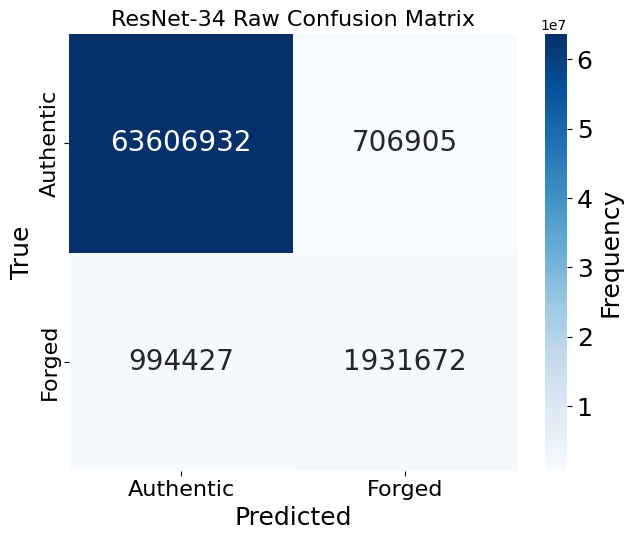

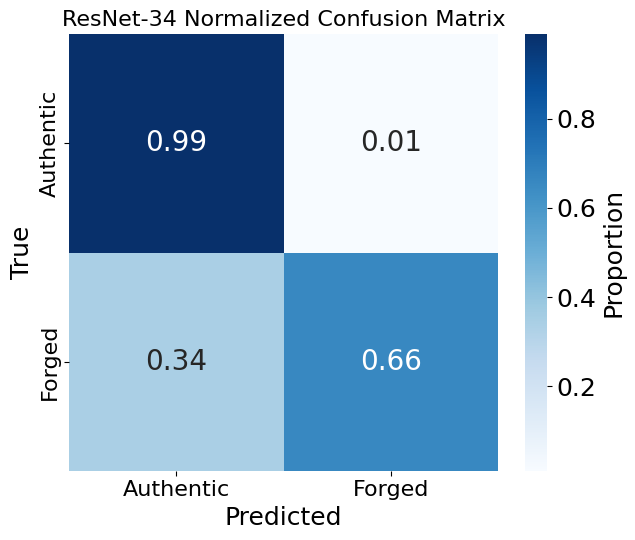

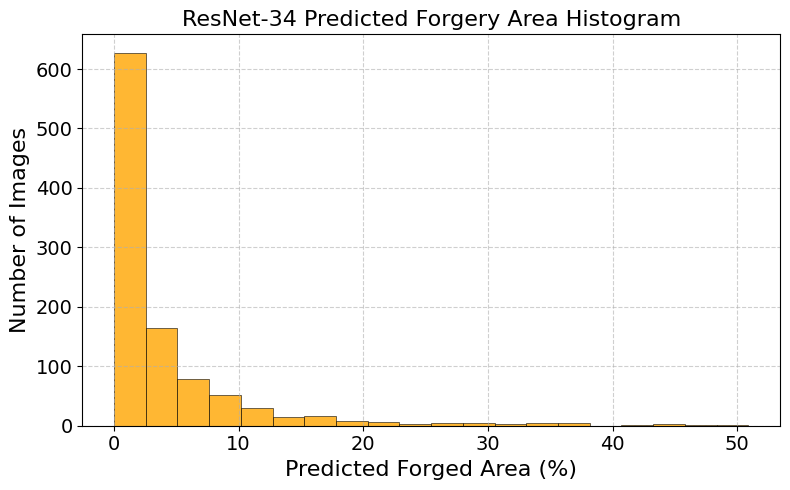


✅ TEST SET EVALUATION COMPLETE — RESNET-34 RESULTS
Mean predicted forgery area: 3.92%
Localization IoU           : 0.3741
Centroid Error (px)        : 43.67

📁 Plots saved to          : /home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34


In [ ]:
# ============================================================
# COMPLETE FORGERY DETECTION EVALUATION (CPU-SAFE & EXACT SPLIT) - RESNET-34
# - Recreates exact sequential split (20% Val, 25% Test from Train)
# - Evaluates validation set and test set securely on CPU
# - Generates confusion matrices, histograms, and localization metrics
# ============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    precision_score, recall_score, f1_score,
    matthews_corrcoef, hamming_loss
)
from collections import Counter
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.spatial.distance import euclidean
import segmentation_models_pytorch as smp
import cv2

IMG_SIZE = (256, 256)
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2
RANDOM_STATE = 42

BASE_DIR_TRAIN = Path("/home/rab/Downloads/forgery_data2_")
TRAIN_IMAGE_DIR = BASE_DIR_TRAIN / "train_images"
TRAIN_MASK_DIR  = BASE_DIR_TRAIN / "train_masks"

# Dedicated separate output directory for ResNet-34 evaluation results
OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi/evaluation_results_resnet34"
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
MODEL_SAVE_PATH = os.path.join(MODEL_DIR, "resnet34_model.pth")

# 🔴 Force CPU for evaluation to bypass GPU OOM issues
DEVICE = torch.device("cpu")
print(f"⚠️ Running evaluation on: {DEVICE}")

# -----------------------------
# DATASET & EXACT SEQUENTIAL SPLIT
# -----------------------------
def find_mask_file(mask_dir, img_name):
    stem = Path(img_name).stem
    for p in [f"{stem}.npy", f"{stem}_mask.npy"]:
        path = os.path.join(mask_dir, p)
        if os.path.exists(path):
            return path
    for root, _, files in os.walk(mask_dir):
        for f in files:
            if Path(f).stem == stem:
                return os.path.join(root, f)
    return None

def load_mask_safe(mask_path, target_shape):
    if mask_path is None or not os.path.exists(mask_path):
        return np.zeros(target_shape, dtype=np.uint8)
    mask = np.squeeze(np.load(mask_path, allow_pickle=True))
    if mask.ndim > 2:
        mask = mask[..., 0]
    mask = (mask > 0.5).astype(np.uint8)
    if mask.shape != target_shape:
        mask = cv2.resize((mask * 255).astype(np.uint8), (target_shape[1], target_shape[0]), interpolation=cv2.INTER_NEAREST)
        mask = (mask > 127).astype(np.uint8)
    return mask

class ForgerySegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, img_size=IMG_SIZE):
        self.img_size = img_size
        self.image_paths = []
        for folder in ["authentic", "forged"]:
            folder_path = Path(image_dir) / folder
            if folder_path.is_dir():
                for file in sorted(os.listdir(folder_path)):
                    if file.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                        self.image_paths.append(str(folder_path / file))
        self.mask_paths = [find_mask_file(mask_dir, Path(x).name) for x in self.image_paths]

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = cv2.imread(self.image_paths[index])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (self.img_size[1], self.img_size[0]))
        mask = load_mask_safe(self.mask_paths[index], (self.img_size[0], self.img_size[1]))
        image = torch.from_numpy(image.transpose(2, 0, 1)).float() / 255.0
        mask = torch.from_numpy(mask).unsqueeze(0).float()
        return image, mask

def get_image_class_from_path(img_path):
    return 1 if "forged" in Path(img_path).parts else 0

print("Loading dataset and recreating exact sequential split...")
dataset = ForgerySegmentationDataset(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
targets = [get_image_class_from_path(p) for p in dataset.image_paths]

# Step 1: 20% validation set, 80% training pool
train_pool_idx, val_idx = train_test_split(
    list(range(len(dataset))),
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=targets
)

# Step 2: 25% test set from the training pool
train_pool_targets = [targets[i] for i in train_pool_idx]
train_idx, test_idx = train_test_split(
    train_pool_idx,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=train_pool_targets
)

val_subset = Subset(dataset, val_idx)
test_subset = Subset(dataset, test_idx)

val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

# -----------------------------
# RE-INITIALIZE & LOAD RESNET-34 MODEL
# -----------------------------
print("Loading trained ResNet-34 model architecture and weights...")
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded ResNet-34 model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}. Please run training first.")

# -----------------------------
# METRIC HELPERS & REUSABLE FUNCTION
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

def compute_centroid(mask):
    coords = np.column_stack(np.where(mask > 0))
    return coords.mean(axis=0) if coords.shape[0] > 0 else None

def compute_classwise_metrics(model, loader, device, threshold=0.5):
    model.eval()
    stats = {
        0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},
        1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},
    }
    y_true_all, y_pred_all = [], []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Computing Class-wise Metrics"):
            images = images.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.float32)

            logits = model(images)
            if logits.shape != masks.shape:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')

            probs = torch.sigmoid(logits)
            preds = (probs > threshold).long()
            gt = masks.long()

            gt_f = gt.view(-1).cpu().numpy()
            pred_f = preds.view(-1).cpu().numpy()

            y_true_all.append(gt_f)
            y_pred_all.append(pred_f)

            for cls in [0, 1]:
                tp = np.sum((pred_f == cls) & (gt_f == cls))
                fp = np.sum((pred_f == cls) & (gt_f != cls))
                fn = np.sum((pred_f != cls) & (gt_f == cls))
                tn = np.sum((pred_f != cls) & (gt_f != cls))

                stats[cls]["tp"] += tp
                stats[cls]["fp"] += fp
                stats[cls]["fn"] += fn
                stats[cls]["tn"] += tn

    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    results = {}
    for cls, name in zip([0, 1], ["Authentic", "Forged"]):
        tp = stats[cls]["tp"]
        fp = stats[cls]["fp"]
        fn = stats[cls]["fn"]
        tn = stats[cls]["tn"]

        dice = dice_score(tp, fp, fn)
        iou = iou_score(tp, fp, fn)
        mcc = matthews_corrcoef((y_true_all == cls).astype(int), (y_pred_all == cls).astype(int))
        h_loss = hamming_loss((y_true_all == cls).astype(int), (y_pred_all == cls).astype(int))

        results[name] = {
            "Dice": dice,
            "IoU": iou,
            "MCC": mcc,
            "Hamming Loss": h_loss
        }

    results["Macro Average"] = {
        m: np.mean([results["Authentic"][m], results["Forged"][m]])
        for m in ["Dice", "IoU", "MCC", "Hamming Loss"]
    }
    return results, y_true_all, y_pred_all

# -----------------------------
# 1. VALIDATION SET EVALUATION
# -----------------------------
print("\n" + "="*80)
print("🔍 EVALUATING ON VALIDATION SET")
print("="*80)
val_metrics, _, _ = compute_classwise_metrics(model, val_loader, DEVICE, threshold=THRESHOLD)
for cls, vals in val_metrics.items():
    print(f"\n{cls}")
    for k, v in vals.items():
        print(f"  {k:15s}: {v:.4f}")

# -----------------------------
# 2. TEST SET DEEP EVALUATION & PLOTS
# -----------------------------
print("\n" + "="*80)
print("🔍 EVALUATING ON TEST SET (Localization, Centroids, Plots)")
print("="*80)

model.eval()
y_true_flat_all, y_pred_flat_all = [], []
stats = {0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}, 1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0}}

ious_loc, centroid_errors, gt_area_pcts, pred_area_pcts, abs_area_errs = [], [], [], [], []
tcrs, fars = [], []
gt_pixel_counts, pred_pixel_counts, pred_area_fractions = [], [], []

with torch.no_grad():
    for images, masks in tqdm(test_loader, desc="Test Set Inference"):
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.float32)

        logits = model(images)
        if logits.shape != masks.shape:
            masks = F.interpolate(masks, size=logits.shape[2:], mode="nearest")

        probs = torch.sigmoid(logits)
        preds_bin = (probs > THRESHOLD).float()

        gt_flat = masks.view(-1).cpu().numpy()
        pred_flat = preds_bin.view(-1).cpu().numpy()
        y_true_flat_all.append(gt_flat)
        y_pred_flat_all.append(pred_flat)

        for cls in [0, 1]:
            stats[cls]["tp"] += np.sum((pred_flat == cls) & (gt_flat == cls))
            stats[cls]["fp"] += np.sum((pred_flat == cls) & (gt_flat != cls))
            stats[cls]["fn"] += np.sum((pred_flat != cls) & (gt_flat == cls))
            stats[cls]["tn"] += np.sum((pred_flat != cls) & (gt_flat != cls))

        pred_flat_batch = preds_bin.view(preds_bin.size(0), -1)
        frac_batch = pred_flat_batch.sum(dim=1) / pred_flat_batch.shape[1]
        pred_area_fractions.extend(frac_batch.cpu().numpy())

        for i in range(images.size(0)):
            gt = masks[i, 0].cpu().numpy().astype(np.uint8)
            pred = preds_bin[i, 0].cpu().numpy().astype(np.uint8)
            H, W = gt.shape
            total_px = H * W
            gt_px, pred_px = int(gt.sum()), int(pred.sum())

            gt_pixel_counts.append(gt_px)
            pred_pixel_counts.append(pred_px)

            inter = np.logical_and(gt, pred).sum()
            union = np.logical_or(gt, pred).sum()
            ious_loc.append((inter + 1e-7) / (union + 1e-7))

            gc, pc = compute_centroid(gt), compute_centroid(pred)
            if gc is not None and pc is not None:
                centroid_errors.append(euclidean(gc, pc))

            gt_area_pct = gt_px / total_px * 100.0
            pred_area_pct = pred_px / total_px * 100.0
            gt_area_pcts.append(gt_area_pct)
            pred_area_pcts.append(pred_area_pct)
            abs_area_errs.append(abs(pred_area_pct - gt_area_pct))

            if gt_px > 0:
                tcrs.append(np.logical_and(pred == 1, gt == 1).sum() / gt_px)
            else:
                tcrs.append(np.nan)

            auth_px = total_px - gt_px
            if auth_px > 0:
                fars.append(np.logical_and(pred == 1, gt == 0).sum() / auth_px)
            else:
                fars.append(np.nan)

y_true_flat_all = np.concatenate(y_true_flat_all)
y_pred_flat_all = np.concatenate(y_pred_flat_all)
pred_area_percentages = np.array(pred_area_fractions) * 100

# Safe Relative Area Diff
gt_pixel_counts = np.array(gt_pixel_counts)
pred_pixel_counts = np.array(pred_pixel_counts)
valid_mask = gt_pixel_counts > 0
if np.any(valid_mask):
    rel_area_diffs = np.abs(pred_pixel_counts[valid_mask] - gt_pixel_counts[valid_mask]) / gt_pixel_counts[valid_mask] * 100.0
    rel_area_diffs = rel_area_diffs[np.isfinite(rel_area_diffs)]
    rel_area_mean = np.mean(rel_area_diffs) if len(rel_area_diffs) > 0 else np.nan
    if not np.isnan(rel_area_mean) and rel_area_mean > 1000:
        rel_area_mean = 1000.0
else:
    rel_area_mean = np.nan

# Confusion Matrices & Plots
cm_raw = confusion_matrix(y_true_flat_all, y_pred_flat_all, labels=[0, 1])
cm_norm = cm_raw.astype(float) / cm_raw.sum(axis=1, keepdims=True)

def save_cm_plot(cm, title, filename, normalize=False):
    plt.figure(figsize=(6.5, 5.5))
    annot = cm if not normalize else np.around(cm, decimals=2)
    fmt = "d" if not normalize else ".2f"

    ax = sns.heatmap(
        cm, annot=annot, fmt=fmt, cmap="Blues", cbar=True,
        xticklabels=["Authentic", "Forged"], yticklabels=["Authentic", "Forged"],
        annot_kws={"size": 20}
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label("Frequency" if not normalize else "Proportion", size=18)
    plt.xlabel("Predicted", fontsize=18)
    plt.ylabel("True", fontsize=18)
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.title(title, fontsize=16)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, filename), dpi=300, bbox_inches='tight')
    plt.show()
    plt.close()

save_cm_plot(cm_raw, "ResNet-34 Raw Confusion Matrix", "resnet34_cm_raw.png", normalize=False)
save_cm_plot(cm_norm, "ResNet-34 Normalized Confusion Matrix", "resnet34_cm_norm.png", normalize=True)

# Histogram Plot
plt.figure(figsize=(8, 5))
plt.hist(pred_area_percentages, bins=20, color='orange', alpha=0.8, edgecolor='black', linewidth=0.5)
plt.xlabel("Predicted Forged Area (%)", fontsize=16)
plt.ylabel("Number of Images", fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.title("ResNet-34 Predicted Forgery Area Histogram", fontsize=16)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "resnet34_predicted_area_hist.png"), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Aggregate Metrics
prec = precision_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
rec = recall_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
f1 = f1_score(y_true_flat_all, y_pred_flat_all, average=None, zero_division=0)
prec_macro = precision_score(y_true_flat_all, y_pred_flat_all, average="macro")
rec_macro = recall_score(y_true_flat_all, y_pred_flat_all, average="macro")
f1_macro = f1_score(y_true_flat_all, y_pred_flat_all, average="macro")

loc_metrics = {
    "Localization IoU": np.nanmean(ious_loc),
    "Centroid Error (px)": np.nanmean(centroid_errors) if centroid_errors else np.nan,
    "Avg GT Forged Area (%)": np.mean(gt_area_pcts),
    "Avg Pred Forged Area (%)": np.mean(pred_area_pcts),
    "Abs Area Error (%)": np.mean(abs_area_errs),
    "Rel Area Diff (%)": rel_area_mean,
    "TCR": np.nanmean(tcrs),
    "FAR": np.nanmean(fars),
}

# Print Test Results Summary
print("\n" + "="*80)
print("✅ TEST SET EVALUATION COMPLETE — RESNET-34 RESULTS")
print("="*80)
print(f"Mean predicted forgery area: {pred_area_percentages.mean():.2f}%")
print(f"Localization IoU           : {loc_metrics['Localization IoU']:.4f}")
print(f"Centroid Error (px)        : {loc_metrics['Centroid Error (px)']:.2f}")
print(f"\n📁 Plots saved to          : {OUTPUT_DIR}")
print("="*80)

In [ ]:
# ============================================================
# EVALUATION ON PREVIOUSLY SPLIT TEST DATASET (RESNET-34)
# ============================================================

import os
import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import Subset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import matthews_corrcoef, hamming_loss
from pathlib import Path
from tqdm import tqdm
import segmentation_models_pytorch as smp

# -----------------------------
# Configuration
# -----------------------------
THRESHOLD = 0.5
BATCH_SIZE = 4
NUM_WORKERS = 2
RANDOM_STATE = 42

OUTPUT_DIR = "/home/rab/Downloads/forgery_10_octiber_effi"
MODEL_SAVE_PATH = os.path.join(OUTPUT_DIR, "resnet34_model.pth")
DEVICE = torch.device("cpu")  # Using CPU to bypass any shared VRAM limits

print(f"⚠️ Running ResNet-34 evaluation on: {DEVICE}")

# -----------------------------
# Recreate Test Split (if needed)
# -----------------------------
def get_image_class(img_path):
    parts = Path(img_path).parts
    if "authentic" in parts:
        return 0
    elif "forged" in parts:
        return 1
    else:
        raise ValueError(f"Unknown class for {img_path}")

if 'test_idx' not in globals():
    targets = [get_image_class(dataset.image_paths[i]) for i in range(len(dataset))]
    train_pool_idx, _ = train_test_split(
        list(range(len(dataset))),
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=targets
    )
    train_pool_targets = [targets[i] for i in train_pool_idx]
    _, test_idx = train_test_split(
        train_pool_idx,
        test_size=0.25,
        random_state=RANDOM_STATE,
        stratify=train_pool_targets
    )

test_subset = Subset(dataset, test_idx)
test_loader = DataLoader(
    test_subset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=False
)

# -----------------------------
# Load Model Weights
# -----------------------------
print("Loading trained ResNet-34 model architecture and weights...")
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=1,
    decoder_channels=(256, 128, 64, 32, 16),
).to(DEVICE)

if os.path.exists(MODEL_SAVE_PATH):
    model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))
    print(f"✅ Successfully loaded ResNet-34 model weights from: {MODEL_SAVE_PATH}")
else:
    raise FileNotFoundError(f"Model weights not found at {MODEL_SAVE_PATH}. Please run training first.")

# -----------------------------
# Dice and IoU helper functions
# -----------------------------
def dice_score(tp, fp, fn, eps=1e-7):
    return (2 * tp + eps) / (2 * tp + fp + fn + eps)

def iou_score(tp, fp, fn, eps=1e-7):
    return (tp + eps) / (tp + fp + fn + eps)

# -----------------------------
# Compute class-wise metrics
# -----------------------------
def compute_classwise_metrics(model, loader, device, threshold=0.5):
    model.eval()

    # Accumulators for each class
    stats = {
        0: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},  # Authentic
        1: {"tp": 0, "fp": 0, "fn": 0, "tn": 0},  # Forged
    }

    y_true_all = []
    y_pred_all = []

    with torch.no_grad():
        for images, masks in tqdm(loader, desc="Computing Class-wise Metrics"):
            images = images.to(device, dtype=torch.float32)
            masks  = masks.to(device, dtype=torch.float32)

            logits = model(images)
            if logits.shape != masks.shape:
                masks = F.interpolate(masks, size=logits.shape[2:], mode='nearest')

            probs = torch.sigmoid(logits)
            preds = (probs > threshold).long()
            gt = masks.long()

            # Flatten
            gt_f   = gt.view(-1).cpu().numpy()
            pred_f = preds.view(-1).cpu().numpy()

            y_true_all.append(gt_f)
            y_pred_all.append(pred_f)

            for cls in [0, 1]:
                tp = np.sum((pred_f == cls) & (gt_f == cls))
                fp = np.sum((pred_f == cls) & (gt_f != cls))
                fn = np.sum((pred_f != cls) & (gt_f == cls))
                tn = np.sum((pred_f != cls) & (gt_f != cls))

                stats[cls]["tp"] += tp
                stats[cls]["fp"] += fp
                stats[cls]["fn"] += fn
                stats[cls]["tn"] += tn

    # Concatenate for MCC & Hamming
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)

    results = {}

    for cls, name in zip([0, 1], ["Authentic", "Forged"]):
        tp = stats[cls]["tp"]
        fp = stats[cls]["fp"]
        fn = stats[cls]["fn"]
        tn = stats[cls]["tn"]

        dice = dice_score(tp, fp, fn)
        iou  = iou_score(tp, fp, fn)

        # MCC (binary per class)
        mcc = matthews_corrcoef(
            (y_true_all == cls).astype(int),
            (y_pred_all == cls).astype(int)
        )

        # Hamming loss
        h_loss = hamming_loss(
            (y_true_all == cls).astype(int),
            (y_pred_all == cls).astype(int)
        )

        results[name] = {
            "Dice": dice,
            "IoU": iou,
            "MCC": mcc,
            "Hamming Loss": h_loss
        }

    # Combined (macro average)
    results["Macro Average"] = {
        m: np.mean([results["Authentic"][m], results["Forged"][m]])
        for m in ["Dice", "IoU", "MCC", "Hamming Loss"]
    }

    return results

# -----------------------------
# Execute class-wise metrics on test_loader
# -----------------------------
metrics = compute_classwise_metrics(model, test_loader, DEVICE, threshold=THRESHOLD)

# -----------------------------
# Print results
# -----------------------------
print("\n" + "="*50)
print("✅ CLASS-WISE TEST METRICS (RESNET-34)")
print("="*50)
for cls, vals in metrics.items():
    print(f"\n{cls}")
    for k, v in vals.items():
        print(f"  {k:15s}: {v:.4f}")
print("="*50)

/tmp/ipykernel_12604/2355645813.py:80: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=DEVICE))


⚠️ Running ResNet-34 evaluation on: cpu
Loading trained ResNet-34 model architecture and weights...
✅ Successfully loaded ResNet-34 model weights from: /home/rab/Downloads/forgery_10_octiber_effi/resnet34_model.pth


Computing Class-wise Metrics: 100%|██████████| 257/257 [00:21<00:00, 11.91it/s]



✅ CLASS-WISE TEST METRICS (RESNET-34)

Authentic
  Dice           : 0.9868
  IoU            : 0.9739
  MCC            : 0.6821
  Hamming Loss   : 0.0253

Forged
  Dice           : 0.6943
  IoU            : 0.5317
  MCC            : 0.6821
  Hamming Loss   : 0.0253

Macro Average
  Dice           : 0.8405
  IoU            : 0.7528
  MCC            : 0.6821
  Hamming Loss   : 0.0253
